# BYOC (Bring Your Own Clean-energy): constraints, system cost and comparison with `base_nodc` and `base_dc`

1. **Constraints** of the BYOC scenario, and whether the new investments have to be in the same country as the new data-centre load.
2. **Total system cost** of BYOC, including a check of the method "`base_nodc` cost + BYOC cost".
3. **Comparison table** of `base_nodc`, `base_dc` and BYOC: system cost, CO2 emissions, curtailment and marginal electricity cost.
4. **Installed capacity** of BYOC per country and technology type.
5. **Generation** of BYOC per country and technology type.

All runs are read from their results GDX (`MainResults*.gdx`); the notebook only needs to be placed in the folder that contains `base_nodc`, `base_dc` and `BYOC`.

In [31]:
# 0.1 Settings, results of the three runs and helpers
from pathlib import Path
import re
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pybalmorel import MainResults

ROOT = Path.cwd() if (Path.cwd() / "BYOC").exists() else Path.cwd().parent       # folder containing the scenario folders
REFERENCE, BASE_DC, BYOC = "base_nodc", "base_dc", "BYOC"
RUNS = {                                                                           # label: (model folder, results file)
    REFERENCE: ("base_nodc/model", "MainResults_fullweek.gdx"),
    BASE_DC:   ("base_dc/model",   "MainResults_fullweek.gdx"),
    BYOC:      ("BYOC/model",      "MainResults.gdx"),
}

res = {}
for run, (folder, file) in RUNS.items():
    if not (ROOT / folder / file).exists():
        raise FileNotFoundError(f"Results of {run} not found: {ROOT / folder / file}")
    res[run] = MainResults(files=file, paths=str(ROOT / folder), scenario_names=[run])

# pybalmorel returns some symbols with the raw GAMS column names; map them to one naming scheme
RENAME = {"Y": "Year", "C": "Country", "RRR": "Region", "AAA": "Area", "G": "Generation", "FFF": "Fuel",
          "TECH_TYPE": "Technology", "COMMODITY": "Commodity", "CATEGORY": "Category",
          "SUBCATEGORY": "Subcategory", "UNITS": "Unit"}

def get(run, symbol):
    """Result symbol of one run as a DataFrame with standard column names and string years."""
    df = res[run].get_result(symbol).rename(columns=RENAME)
    return df[df["Scenario"] == run].assign(Year=lambda d: d["Year"].astype(str))

YEARS = sorted(set.intersection(*[set(get(run, "OBJ_YCR")["Year"]) for run in RUNS]), key=int)     # years solved in all runs
print(f"Years solved in all three runs: {', '.join(YEARS)}")

# Technology types folded into groups (same grouping and colours as NOTEBOOK_PostProcessing)
TECH_GROUP = {
    "WIND-ON": "Onshore wind", "WIND-OFF": "Offshore wind",
    "SOLAR-PV": "Solar", "SOLAR-HEATING": "Solar",
    "HYDRO-RESERVOIRS": "Hydro", "HYDRO-RUN-OF-RIVER": "Hydro",
    "GNR_ST_NUCL_CND_E-33": "Nuclear",
    "GNR_BO_HYDROGEN_E-90": "Hydrogen", "GNR_ST_HYDROGEN_BP_CB-30": "Hydrogen",
    "CHP-BACK-PRESSURE": "CHP", "CHP-EXTRACTION": "CHP",
    "BOILERS": "Boilers",
    "ELECT-TO-HEAT": "Conversion", "ELECTROLYZER": "Conversion",
    "STEAMREFORMING": "Conversion", "BIOGASUPGRADING": "Conversion",
    "INTRASEASONAL-HEAT-STORAGE": "Heat storage", "INTERSEASONAL-HEAT-STORAGE": "Heat storage",
    "INTRASEASONAL-ELECT-STORAGE": "Electricity storage", "H2-STORAGE": "H2 storage",
    "FUELCELL": "Hydrogen fuel cell",
}
GROUP_COLORS = {"Onshore wind": "#2a78d6", "Offshore wind": "#1769aa", "Solar": "#eb6834", "Hydro": "#1baf7a", "Nuclear": "#6f42c1",
                "Biogas": "#8c6bb1", "Biomass": "#5a9e3d", "Heat": "#d1495b", "Hydrogen": "#00a6a6", "Natgas-CCS": "#7f7f7f", "CHP": "#eda100",
                "Natural gas": "#9aa0a6", "Coal & lignite": "#3b3b3b", "Oil": "#8a5a2b", "Waste": "#b08968", "Other condensing": "#e87ba4", "Boilers": "#008300", "Conversion": "#4a3aa7",
                "Battery storage": "#e34948", "Pumped hydro storage": "#8c2d2d", "Electricity storage": "#c97a7a",
                "Heat storage": "#f08a5d", "H2 storage": "#7fd1d1", "Hydrogen fuel cell": "#b0e000",
                "Other": "#9a9992"}

# Condensing plants are split by fuel (the technology type CONDENSING covers nuclear, gas, biomass, waste, ...)
CONDENSING_FUEL_GROUP = {"NUCLEAR": "Nuclear", "NATGAS": "Natural gas", "COAL": "Coal & lignite", "LIGNITE": "Coal & lignite",
                         "PEAT": "Coal & lignite", "SHALE": "Coal & lignite", "COKE": "Coal & lignite",
                         "FUELOIL": "Oil", "LIGHTOIL": "Oil", "HEAVYFUELOIL": "Oil",
                         "BIOGAS": "Biogas", "WOOD": "Biomass", "WOODCHIPS": "Biomass", "WOODPELLETS": "Biomass", "WOODWASTE": "Biomass",
                         "STRAW": "Biomass", "BIOOIL": "Biomass",
                         "MUNIWASTE": "Waste", "HAZARDOUSWASTE": "Waste", "WASTEHEAT": "Waste"}

def tech_group(df):
    """Technology group per row."""
    technology = df["Technology"].fillna("").astype(str).str.upper()
    group = df["Technology"].map(TECH_GROUP).fillna("Other")
    group = group.mask(technology.str.contains("NGASCCS|NATGASCCS"), "Natgas-CCS")
    group = group.mask(technology.str.contains("WIND_OFF|WIND-OFF"), "Offshore wind")
    group = group.mask(technology.str.contains("WIND_ON|WIND-ON"), "Onshore wind")
    group = group.mask(technology.str.contains("BGAS|BIOGAS"), "Biogas")
    group = group.mask(technology.str.contains("WOOD|STRAW|BIOIL|BIOFUEL|PELLET|CHIP"), "Biomass")
    group = group.mask(technology.str.contains("HYDROGEN|GH2"), "Hydrogen")
    group = group.mask(technology.str.contains("HEAT") & ~technology.str.contains("STORAGE"), "Heat")
    # Condensing plants by fuel; gas plants with CCS (CCS in the generator name) are their own group
    condensing = technology.eq("CONDENSING")
    fuel = df["Fuel"].fillna("").astype(str).str.upper()
    by_fuel = fuel.map(CONDENSING_FUEL_GROUP).fillna("Other condensing")
    by_fuel = by_fuel.mask(by_fuel.eq("Natural gas") & df["Generation"].fillna("").astype(str).str.upper().str.contains("NGASCCS|NATGASCCS"), "Natgas-CCS")
    group = group.mask(condensing, by_fuel)
    # Electricity storage: pumped hydro (generator names with WTR_PMP) versus batteries (BAT-...)
    generator = df["Generation"].fillna("").astype(str).str.upper()
    electricity_storage = technology.eq("INTRASEASONAL-ELECT-STORAGE")
    group = group.mask(electricity_storage & generator.str.contains("WTR_PMP"), "Pumped hydro storage")
    group = group.mask(electricity_storage & generator.str.contains("BAT"), "Battery storage")
    return group

def clean_name(s):
    return str(s).replace("_", " ").title()

Loading /work3/s243704/Balmorel/base_nodc/model/MainResults_fullweek.gdx
Loading /work3/s243704/Balmorel/base_dc/model/MainResults_fullweek.gdx
Loading /work3/s243704/Balmorel/BYOC/model/MainResults.gdx
Years solved in all three runs: 2025, 2030, 2035


## 1. Constraints set in BYOC

Source: `BYOC/data/BYOC_apply.inc`, `BYOC/data/BYOC_settings.inc`, `BYOC/model/balopt.opt` and `BYOC/model/bb4datainc.inc`. The idea: the data centres are served by **new renewables and storage only**, on top of the system of `base_nodc`.

| # | Constraint | How it is set | Geographical scope |
|---|---|---|---|
| 1 | **Reference system is fixed** | The net capacity of `base_nodc` (`GKFX + VGKNACCUMNET - VDECOM_EXO_ACCUM` from `all_endofmodel_fullweek.gdx`) becomes exogenous capacity `GKFX` and replaces all other exogenous capacity. The model aborts if a simulated year is missing in the reference run. | Every area, same capacity as in `base_nodc` |
| 2 | **No new fossil or nuclear capacity** | `AGKN(AAA,G) = NO` for every technology whose fuel is in `BYOC_NONRENEWABLE_FUELS` (nuclear, gas, coal, lignite, oil, peat, waste, ... and CCS variants). Wind, solar, hydro, geothermal, ambient heat, biomass and biogas, storage, heat pumps etc. stay investable. | Every area where the base data allow an investment |
| 3 | **No extra fossil fuel use** | `GMAXF` limits the annual use of each non-renewable fuel to the use of `base_nodc` (`F_CONS_YCRA`) times `1 + BYOC_FUELCAP_TOL`. Fuels that `base_nodc` did not use get an `EPS` limit (= zero). An existing tighter `GMAXF` limit is kept. | `BYOC_FUELCAP_LEVEL` (default `REGION`): fuel use can be moved between areas of a region, **not** between regions or countries |
| 4 | **No decommissioning games on the reference capacity** | `balopt.opt` switches off `NO_DECOM_EXO_G`, `LIFETIME_DECOM_EXO_G`, `ECONOMIC_DECOM_EXO_G` and `REVERT_DECOM_EXO_G`, so retired fossil plants cannot come back. Decommissioning of new investments is kept. | Every area |
| 5 | **No transmission expansion** | `TransInvest` is `NO` in the base options that `balopt.opt` includes. The existing grid is used as is. | Every transmission line |

### Does the new investment have to be in the same country as the new load?

**No.** None of the constraints links an investment to the location of the data centres: there is no country, region or area matching, and also no hourly or annual matching of supply and load. The data-centre load is an additional electricity demand of its region; the new renewables and storage are built wherever the model finds it cheapest (subject to the unchanged investment potentials of the base data and constraints 2 and 3) and reach the load through the **existing** transmission grid (constraint 5). Only the fuel limit (3) has a geographical level, and it restricts fossil fuel use, not renewable investments.

The next cell checks this in the results: it compares the extra load per country with the new capacity per country.

In [32]:
# 1.1 Live settings from BYOC_settings.inc and where the new capacity is built relative to the extra data-centre load
settings = (ROOT / "BYOC" / "data" / "BYOC_settings.inc").read_text()
def byoc_setting(name):
    return re.search(rf"\$setglobal\s+{name}\s+(\S+)", settings).group(1)

print(f"Reference run (BYOC_REF_DIR)      : {byoc_setting('BYOC_REF_DIR')}")
print(f"Level of the fuel limit           : {byoc_setting('BYOC_FUELCAP_LEVEL')}")
print(f"Tolerance on the fuel limit       : {byoc_setting('BYOC_FUELCAP_TOL')}")
print(f"Non-renewable fuels (limited, no new investments): {byoc_setting('BYOC_NONRENEWABLE_FUELS').replace(',', ', ')}")

# Extra load per country = exogenous electricity demand of BYOC minus base_nodc (TWh); new capacity = ENDOGENOUS electricity capacity of BYOC (GW)
def by_country(run, symbol, query):
    t = get(run, symbol).query(query)
    return t.groupby(["Year", "Country"])["Value"].sum()

extra_load = (by_country(BYOC, "EL_DEMAND_YCR", "Category == 'EXOGENOUS'")
              - by_country(REFERENCE, "EL_DEMAND_YCR", "Category == 'EXOGENOUS'")).rename("Extra load (TWh)")
new_cap = by_country(BYOC, "G_CAP_YCRAF", "Category == 'ENDOGENOUS' and Commodity == 'ELECTRICITY'").rename("New electricity capacity (GW)")
location = pd.concat([extra_load, new_cap], axis=1).fillna(0)

rows = []
for year in YEARS:
    t = location.xs(year, level="Year")
    has_load = t["Extra load (TWh)"] > 1e-3
    total = t["New electricity capacity (GW)"].sum()
    rows.append({"Year": year, "Extra load (TWh)": t["Extra load (TWh)"].sum(), "New capacity (GW)": total,
                 "Countries with extra load": int(has_load.sum()), "Countries with new capacity (> 0.01 GW)": int((t["New electricity capacity (GW)"] > 0.01).sum()),
                 "New capacity in countries without extra load (%)": 100 * t.loc[~has_load, "New electricity capacity (GW)"].sum() / total if total > 1e-9 else np.nan})
display(pd.DataFrame(rows).set_index("Year").round(2))

last = YEARS[-1]
display(location.xs(last, level="Year").sort_values("New electricity capacity (GW)", ascending=False).round(2).rename_axis(f"Country ({last})"))

Reference run (BYOC_REF_DIR)      : ../../base_nodc/model
Level of the fuel limit           : REGION
Tolerance on the fuel limit       : 1e-4
Non-renewable fuels (limited, no new investments): NUCLEAR, NATGAS, COAL, LIGNITE, FUELOIL, LIGHTOIL, HEAVYFUELOIL, ORIMULSION, SHALE, PEAT, MUNIWASTE, HAZARDOUSWASTE, LPG, LNG, OTHERGAS, RETORTGAS, COKE, COAL_EXETS, NATGAS_EXETS, FUELOIL_EXETS, LPG_EXETS, HEAVYFUELOIL_EXETS, COAL_CCS, NG_CCS


,Extra load (TWh),New capacity (GW),Countries with extra load,Countries with new capacity (> 0.01 GW),New capacity in countries without extra load (%)
Year,,,,,
2025,0.00,-0.00,0,0,NaN
2030,38.67,16.78,29,26,7.02
2035,131.37,51.60,30,28,0.65


,Extra load (TWh),New electricity capacity (GW)
Country (2035),,
GERMANY,17.83,12.50
UNITED_KINGDOM,14.73,5.86
POLAND,5.58,3.88
SPAIN,7.92,3.74
BELGIUM,3.67,3.65
AUSTRIA,1.32,3.49
ITALY,6.25,3.36
DENMARK,5.92,2.95
IRELAND,8.47,2.19


## 2. Total system cost of BYOC

### Is "`base_nodc` + BYOC" the right method?

**No, it double-counts.** What `OBJ_YCR` of BYOC contains follows from how BYOC is built (section 1, constraint 1):

* The whole reference system is exogenous capacity in BYOC, and the model dispatches the **whole** system (reference load plus data centres). The BYOC objective therefore already holds the fixed O&M, variable O&M, fuel and CO2 cost of the **entire** system, not only of the data-centre part.
* Capital cost is only charged for **new investments**. The investments that `base_nodc` made are exogenous capacity in BYOC and carry no capital cost there.

So BYOC covers the full operating cost, but is **missing the capital cost of the `base_nodc` investments**. Adding the complete `base_nodc` cost would count its fixed O&M, fuel, variable O&M and CO2 cost twice. The consistent system cost of BYOC is

> **BYOC system cost = BYOC `OBJ_YCR` + capital cost of `base_nodc`** (`GENERATION_CAPITAL_COSTS`)

The cell below shows the cost terms of the three runs (the evidence), the result of both methods, and two consistency checks. Hydrogen-pipeline capital cost is not added: BYOC can invest in it itself and reports its own cost (`H2_TRANSMISSION_CAPITAL_COSTS`); electricity transmission capital cost is zero in all runs.

OBJ_YCR per cost term (Mmoney), as reported by each run


base_nodc                     base_dc  \
Year                                     2025     2030      2035     2025   
Category                                                                    
GENERATION_CAPITAL_COSTS              82955.0  92937.0  104813.0  82955.0   
GENERATION_CO2_TAX                    14063.0  14390.0   15488.0  14063.0   
GENERATION_CO2_TRANSPORT                340.0   1127.0    3276.0    340.0   
GENERATION_FIXED_COSTS                83261.0  86038.0   77482.0  83261.0   
GENERATION_FUEL_COSTS                 45599.0  42675.0   50169.0  45599.0   
GENERATION_OPERATIONAL_COSTS          13306.0  13528.0   13356.0  13306.0   
H2_TRANSMISSION_CAPITAL_COSTS             0.0    134.0     207.0      0.0   
H2_TRANSMISSION_OPERATIONAL_COSTS         0.0      0.0       0.0      0.0   
HEAT_TRANSMISSION_OPERATIONAL_COSTS       0.0      0.0       0.0      0.0   
TRANSMISSION_OPERATIONAL_COSTS            0.0      0.0       0.0      0.0   

                                                           BYOC           \
Year                                    2030      2035     2025     2030   
Category                                                                   
GENERATION_CAPITAL_COSTS             93319.0  107049.0     -0.0    835.0   
GENERATION_CO2_TAX                   14583.0   15844.0  14063.0  14403.0   
GENERATION_CO2_TRANSPORT              1168.0    3487.0    340.0   1125.0   
GENERATION_FIXED_COSTS               86357.0   78423.0  83261.0  86271.0   
GENERATION_FUEL_COSTS                43166.0   51638.0  45599.0  43132.0   
GENERATION_OPERATIONAL_COSTS         13595.0   13537.0  13306.0  13543.0   
H2_TRANSMISSION_CAPITAL_COSTS          137.0     200.0      0.0    136.0   
H2_TRANSMISSION_OPERATIONAL_COSTS        0.0       0.0      0.0      0.0   
HEAT_TRANSMISSION_OPERATIONAL_COSTS      0.0       0.0      0.0      0.0   
TRANSMISSION_OPERATIONAL_COSTS           0.0       0.0      0.0      0.0   

                                              
Year                                    2035  
Category                                      
GENERATION_CAPITAL_COSTS              3563.0  
GENERATION_CO2_TAX                   15410.0  
GENERATION_CO2_TRANSPORT              3275.0  
GENERATION_FIXED_COSTS               78459.0  
GENERATION_FUEL_COSTS                51147.0  
GENERATION_OPERATIONAL_COSTS         13545.0  
H2_TRANSMISSION_CAPITAL_COSTS          224.0  
H2_TRANSMISSION_OPERATIONAL_COSTS        0.0  
HEAT_TRANSMISSION_OPERATIONAL_COSTS      0.0  
TRANSMISSION_OPERATIONAL_COSTS           0.0

Total system cost (Mmoney)


,base_nodc,base_dc,BYOC objective only (reported),base_nodc + BYOC (double-counts),BYOC system cost (BYOC + base_nodc capital),BYOC system cost - base_nodc,BYOC system cost - base_dc
Year,,,,,,,
2025,239525.0,239525.0,156569.0,396094.0,239525.0,0.0,-0.0
2030,250830.0,252326.0,159445.0,410275.0,252382.0,1552.0,56.0
2035,264791.0,270178.0,165623.0,430414.0,270436.0,5645.0,258.0


Check 1 (2025): BYOC system cost - base_nodc = +0.0 Mmoney (+0.0000 %)  -> consistent
Check 2: operating cost (all terms except capital, Mmoney). BYOC is of the size of the full system, not of the data-centre part only


,base_nodc,base_dc,BYOC,BYOC / base_dc (%)
Year,,,,
2025,156569.4,156569.4,156569.4,100.0
2030,157759.2,158869.3,158473.8,99.8
2035,159771.0,162928.6,161835.5,99.3


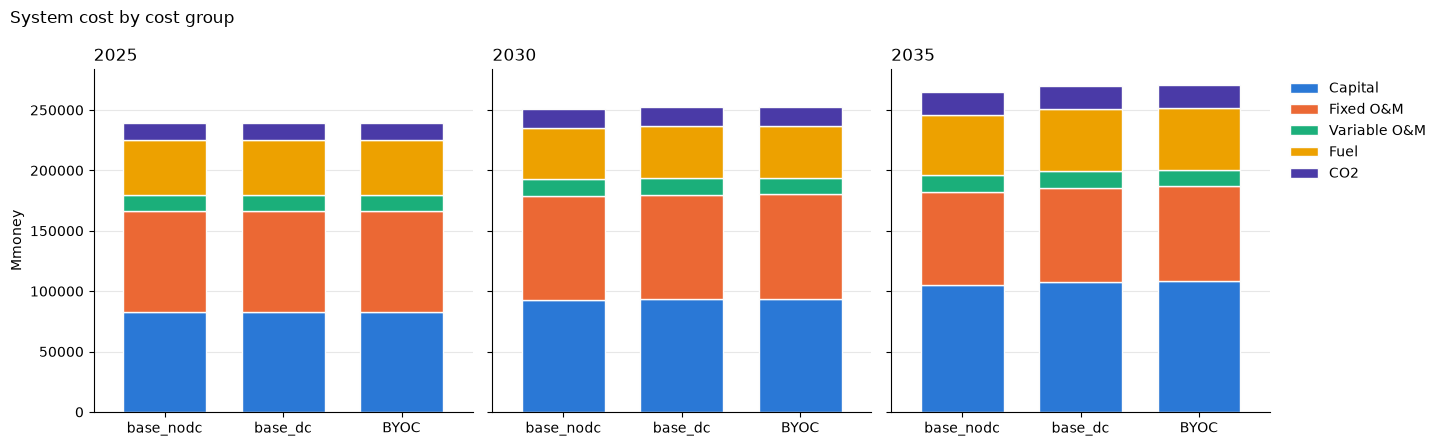

In [33]:
# 2.1 Cost terms per run (Mmoney) and the system cost of BYOC
COST_GROUP = {
    "GENERATION_CAPITAL_COSTS": "Capital", "TRANSMISSION_CAPITAL_COSTS": "Capital", "H2_TRANSMISSION_CAPITAL_COSTS": "Capital",
    "GENERATION_FIXED_COSTS": "Fixed O&M",
    "GENERATION_OPERATIONAL_COSTS": "Variable O&M", "TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M",
    "HEAT_TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M", "H2_TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M",
    "GENERATION_FUEL_COSTS": "Fuel",
    "GENERATION_CO2_TAX": "CO2", "GENERATION_CO2_TRANSPORT": "CO2",
}
COST_COLORS = {"Capital": "#2a78d6", "Fixed O&M": "#eb6834", "Variable O&M": "#1baf7a", "Fuel": "#eda100", "CO2": "#4a3aa7", "Other": "#9a9992"}
SUNK_IN_BYOC = ["GENERATION_CAPITAL_COSTS"]       # capital cost of the base_nodc investments, which are exogenous (cost-free) capacity in BYOC

cost = {run: get(run, "OBJ_YCR").groupby(["Year", "Category"])["Value"].sum().unstack("Category").fillna(0).reindex(YEARS, fill_value=0)
        for run in RUNS}

# Cost terms of the three runs as reported (the evidence for the method)
terms = pd.concat({run: cost[run].T for run in RUNS}, axis=1).fillna(0)
print("OBJ_YCR per cost term (Mmoney), as reported by each run")
display(terms.round(0))

# BYOC system cost: BYOC objective + capital cost of the base_nodc investments
byoc_corrected = cost[BYOC].copy()
for term in SUNK_IN_BYOC:
    byoc_corrected[term] = byoc_corrected.get(term, 0) + cost[REFERENCE].get(term, 0)
cost["BYOC (system cost)"] = byoc_corrected

total = pd.DataFrame({
    "base_nodc": cost[REFERENCE].sum(axis=1),
    "base_dc": cost[BASE_DC].sum(axis=1),
    "BYOC objective only (reported)": cost[BYOC].sum(axis=1),
    "base_nodc + BYOC (double-counts)": cost[REFERENCE].sum(axis=1) + cost[BYOC].sum(axis=1),
    "BYOC system cost (BYOC + base_nodc capital)": byoc_corrected.sum(axis=1),
})
total["BYOC system cost - base_nodc"] = total["BYOC system cost (BYOC + base_nodc capital)"] - total["base_nodc"]
total["BYOC system cost - base_dc"] = total["BYOC system cost (BYOC + base_nodc capital)"] - total["base_dc"]
print("Total system cost (Mmoney)")
display(total.round(0))

# Check 1: in a year without extra load BYOC has no new investment, so its system cost must equal base_nodc
first = YEARS[0]
diff0 = total.loc[first, "BYOC system cost (BYOC + base_nodc capital)"] - total.loc[first, "base_nodc"]
print(f"Check 1 ({first}): BYOC system cost - base_nodc = {diff0:+,.1f} Mmoney ({diff0 / total.loc[first, 'base_nodc'] * 100:+.4f} %)"
      f"  -> {'consistent' if abs(diff0) < 1e-3 * total.loc[first, 'base_nodc'] else 'CHECK: BYOC differs from base_nodc even without extra load'}")

# Check 2: the operating cost (everything except capital) of BYOC must be of the size of base_dc, i.e. it contains the full system
capital = [c for c in cost[BYOC].columns if COST_GROUP.get(c) == "Capital"]
operating = lambda c: c.drop(columns=capital, errors="ignore").sum(axis=1)
check = pd.DataFrame({"base_nodc": operating(cost[REFERENCE]), "base_dc": operating(cost[BASE_DC]), "BYOC": operating(cost[BYOC])})
check["BYOC / base_dc (%)"] = check["BYOC"] / check["base_dc"] * 100
print("Check 2: operating cost (all terms except capital, Mmoney). BYOC is of the size of the full system, not of the data-centre part only")
display(check.round(1))

# Cost by cost group: base_nodc, base_dc and BYOC (system cost)
fig, axes = plt.subplots(1, len(YEARS), figsize=(4.5 * len(YEARS) + 1, 4.5), sharey=True, squeeze=False)
for ax, year in zip(axes.ravel(), YEARS):
    t = pd.DataFrame({label: cost[run].loc[year].groupby(lambda c: COST_GROUP.get(c, "Other")).sum()
                      for label, run in [("base_nodc", REFERENCE), ("base_dc", BASE_DC), ("BYOC", "BYOC (system cost)")]}).T.fillna(0)
    cols = [g for g in COST_COLORS if g in t.columns]
    t[cols].plot.bar(stacked=True, ax=ax, color=[COST_COLORS[c] for c in cols], width=0.7, edgecolor="#fcfcfb", legend=False)
    ax.set_title(year, loc="left"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
axes[0, 0].set_ylabel("Mmoney")
axes[0, -1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.suptitle("System cost by cost group", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## 3. Comparison table: `base_nodc`, `base_dc` and BYOC

* **System cost**: `OBJ_YCR` (Mmoney); BYOC with the capital cost of `base_nodc` added (section 2).
* **CO2 emissions**: `EMI_YCRAG` (kton). BYOC runs the whole system, so its emissions are the system emissions and are not added to `base_nodc`.
* **Curtailment**: onshore wind, offshore wind and solar, in TWh and as % of the available energy (dispatched + curtailed). Hydro rows of `CURT_YCRAGF` net to about zero and are left out, as in `NOTEBOOK_PostProcessing`.
* **Marginal electricity cost**: `EL_PRICE_YCR` (Money/MWh), time-averaged per region and weighted by the annual electricity demand of the region.

The last columns give the difference BYOC - `base_dc` and the same difference in % of `base_dc` (for the curtailment rate this is a relative change, so see the TWh row for the absolute size).

In [34]:
# 3.1 Summary table
VRE_CURT_TECH = ["WIND-ON", "WIND-OFF", "SOLAR-PV"]

def total_by_year(run, symbol, query=None):
    t = get(run, symbol)
    t = t.query(query) if query else t
    return t.groupby("Year")["Value"].sum().reindex(YEARS, fill_value=0)

def marginal_cost(run):
    # Demand-weighted average of EL_PRICE_YCR (Money/MWh) over the regions
    price = get(run, "EL_PRICE_YCR").query("Category == 'AVERAGE'").set_index(["Year", "Region"])["Value"]
    demand = get(run, "EL_DEMAND_YCR").groupby(["Year", "Region"])["Value"].sum()
    t = pd.concat({"P": price, "D": demand}, axis=1).dropna()
    return (t["P"] * t["D"]).groupby("Year").sum().div(t["D"].groupby("Year").sum()).reindex(YEARS)

def summary(run):
    vre = "Technology in @VRE_CURT_TECH and Commodity == 'ELECTRICITY'"
    curtailed, dispatched = total_by_year(run, "CURT_YCRAGF", vre), total_by_year(run, "PRO_YCRAGF", vre)
    system_cost = cost["BYOC (system cost)"].sum(axis=1) if run == BYOC else total_by_year(run, "OBJ_YCR")
    return pd.DataFrame({
        "System cost (Mmoney)": system_cost,
        "CO2 emissions (kton)": total_by_year(run, "EMI_YCRAG"),
        "Curtailment (TWh)": curtailed,
        "Curtailment (% of wind & solar available)": curtailed / (curtailed + dispatched).replace(0, np.nan) * 100,
        "Marginal electricity cost (Money/MWh)": marginal_cost(run),
    })

parts = {run: summary(run) for run in RUNS}
table = pd.concat({run: parts[run].T.stack() for run in RUNS}, axis=1)      # rows: metric x year
table.index = table.index.set_names(["Metric", "Year"])
table["BYOC - base_dc"] = table[BYOC] - table[BASE_DC]
table["BYOC vs base_dc (%)"] = table["BYOC - base_dc"] / table[BASE_DC].replace(0, np.nan) * 100

def color_change(s):
    # red = BYOC is higher than base_dc, green = lower
    return ["color: #c0392b" if v > 0 else "color: #1e8449" if v < 0 else "" for v in s]

styler = (table.style.format("{:,.2f}", subset=[REFERENCE, BASE_DC, BYOC, "BYOC - base_dc"])
          .format("{:+.2f} %", subset=["BYOC vs base_dc (%)"], na_rep="n/a")
          .apply(color_change, subset=["BYOC vs base_dc (%)"]))
display(styler)

## 4. Installed capacity of BYOC per country and technology type

Electricity capacity (GW, `G_CAP_YCRAF`), one bar per country, stacked by technology group (storage is shown with its power capacity). Two views:

* **New capacity (investments)**: the `ENDOGENOUS` category, i.e. what BYOC builds to serve the data centres. 2025 has no investments and is skipped.
* **Total installed capacity**: reference system plus new capacity, minus decommissioning.

Countries are sorted by total capacity. Set `COMMODITY` to `"HEAT"` or `"HYDROGEN"` to plot those technologies instead.

In [35]:
# 4.0 What is in each technology group? BYOC capacity (GW) by group, technology, fuel and example generators, all years and commodities
all_cap = get(BYOC, "G_CAP_YCRAF")
all_cap = all_cap.assign(Group=tech_group(all_cap))
composition = (all_cap[all_cap["Year"] == YEARS[-1]].groupby(["Commodity", "Group", "Technology", "Fuel"])
               .agg(**{f"Capacity {YEARS[-1]} (GW)": ("Value", "sum"),
                       "Generators": ("Generation", lambda g: ", ".join(sorted(set(g))[:3]) + (" ..." if g.nunique() > 3 else ""))}))
display(composition.round(2))
print("Technology types that end up in 'Other':", sorted(all_cap.loc[all_cap["Group"] == "Other", "Technology"].unique()) or "none")

Capacity 2035 (GW)  \
Commodity   Group                Technology                  Fuel                              
ELECTRICITY Battery storage      INTRASEASONAL-ELECT-STORAGE ELECTRIC                   0.16   
            Biogas               CONDENSING                  BIOGAS                     4.18   
            Biomass              CONDENSING                  WOOD                       1.34   
            CHP                  CHP-BACK-PRESSURE           BIOGAS                     0.15   
                                                             HEAT                       0.04   
                                                             MUNIWASTE                  4.64   
                                                             NATGAS                    44.30   
                                                             STRAW                      2.09   
                                                             WOODCHIPS                 13.67   
                                                             WOODPELLETS                0.19   
                                                             WOODWASTE                  0.74   
                                 CHP-EXTRACTION              MUNIWASTE                  0.05   
                                                             NATGAS                     4.41   
                                                             WOOD                       3.59   
            Hydro                HYDRO-RESERVOIRS            WATER                    102.74   
                                 HYDRO-RUN-OF-RIVER          WATER                     73.47   
            Hydrogen fuel cell   FUELCELL                    HYDROGEN                   5.64   
            Natgas-CCS           CONDENSING                  NATGAS                     4.12   
            Natural gas          CONDENSING                  NATGAS                    55.97   
            Nuclear              CONDENSING                  NUCLEAR                   83.17   
            Offshore wind        WIND-OFF                    WIND                      47.32   
            Oil                  CONDENSING                  FUELOIL                    0.83   
            Onshore wind         WIND-ON                     WIND                     635.58   
            Other condensing     CONDENSING                  DUMMY                      0.20   
            Pumped hydro storage INTRASEASONAL-ELECT-STORAGE ELECTRIC                  19.50   
            Solar                SOLAR-PV                    SUN                      605.19   
            Waste                CONDENSING                  MUNIWASTE                  2.17   
                                                             WASTEHEAT                  0.52   
HEAT        Boilers              BOILERS                     BIOGAS                     0.03   
                                                             BIOOIL                     0.02   
                                                             COAL                      16.63   
                                                             FUELOIL                    0.24   
                                                             LIGHTOIL                  32.43   
                                                             MUNIWASTE                  1.49   
                                                             NATGAS                   295.26   
                                                             WASTEHEAT                  0.05   
                                                             WOOD                       0.54   
                                                             WOODCHIPS                148.43   
                                                             WOODWASTE                  7.13   
            CHP                  CHP-BACK-PRESSURE           BIOGAS                     0.20   
                                          

Technology types that end up in 'Other': none


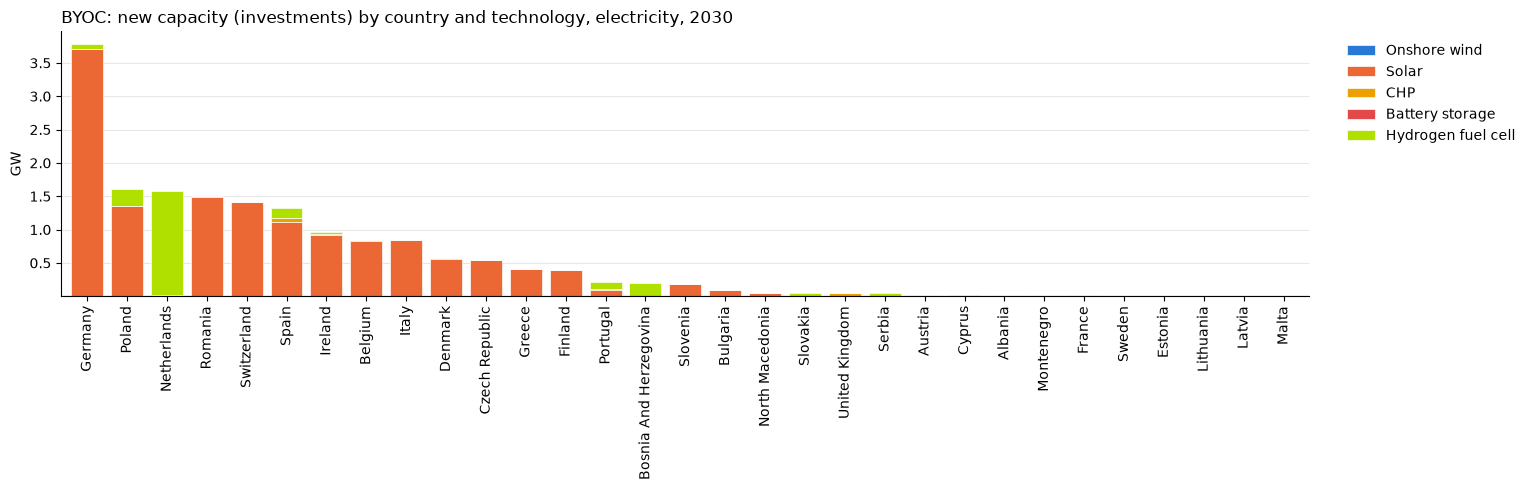

Group,Battery storage,CHP,Hydrogen fuel cell,Onshore wind,Solar,Total
"New capacity (investments), 2030 (GW)",,,,,,
GERMANY,0.00,0.00,0.07,0.0,3.71,3.78
POLAND,0.00,0.00,0.25,0.0,1.36,1.61
NETHERLANDS,0.00,0.02,1.55,0.0,0.00,1.58
ROMANIA,0.00,0.02,0.00,-0.0,1.49,1.51
SWITZERLAND,0.00,0.00,0.00,0.0,1.41,1.41
SPAIN,0.00,0.07,0.14,0.0,1.11,1.32
IRELAND,0.00,0.02,0.02,0.0,0.93,0.97
BELGIUM,0.00,0.01,0.00,0.0,0.83,0.85
ITALY,0.00,-0.00,0.00,0.0,0.85,0.85


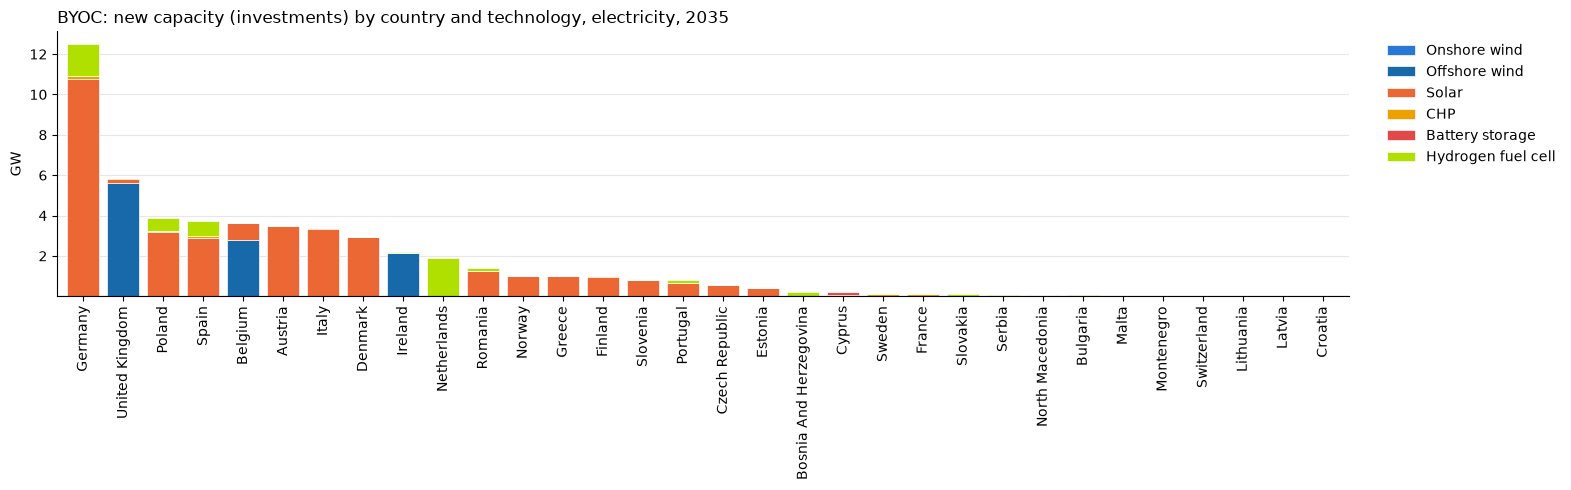

Group,Battery storage,CHP,Hydrogen fuel cell,Offshore wind,Onshore wind,Solar,Total
"New capacity (investments), 2035 (GW)",,,,,,,
GERMANY,0.00,0.13,1.60,0.00,0.0,10.77,12.50
UNITED_KINGDOM,0.00,0.05,0.00,5.63,0.0,0.18,5.86
POLAND,0.00,0.06,0.62,0.00,0.0,3.20,3.88
SPAIN,0.00,0.10,0.75,0.00,0.0,2.88,3.74
BELGIUM,0.00,0.01,0.00,2.80,0.0,0.83,3.65
AUSTRIA,0.00,0.02,0.00,0.00,0.0,3.47,3.49
ITALY,0.00,0.02,0.00,0.00,0.0,3.34,3.36
DENMARK,0.00,0.01,0.00,0.00,0.0,2.94,2.95
IRELAND,0.00,0.02,0.02,2.14,0.0,0.01,2.19


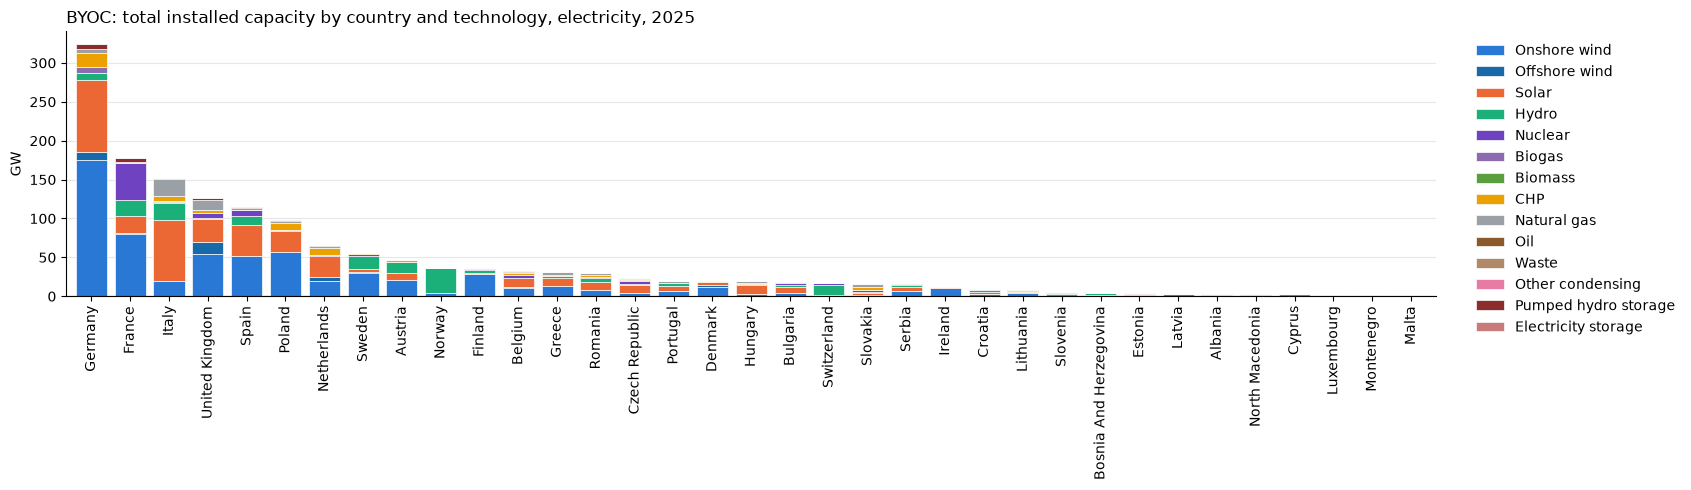

Group,Biogas,Biomass,CHP,Electricity storage,Hydro,Natural gas,Nuclear,Offshore wind,Oil,Onshore wind,Other condensing,Pumped hydro storage,Solar,Waste,Total
"Total installed capacity, 2025 (GW)",,,,,,,,,,,,,,,
GERMANY,7.14,0.00,18.20,0.01,8.97,6.01,0.00,9.22,0.00,175.61,0.00,5.85,93.33,0.04,324.36
FRANCE,0.00,0.00,0.26,0.00,21.00,0.00,48.10,1.48,0.00,80.00,0.00,4.77,21.24,0.68,177.53
ITALY,1.38,1.56,5.85,0.00,21.94,22.33,0.00,0.03,0.00,20.00,0.00,0.51,77.71,0.96,152.26
UNITED_KINGDOM,0.00,0.00,3.98,0.00,1.74,12.65,5.88,15.93,0.00,54.00,0.00,2.86,29.24,0.45,126.73
SPAIN,0.00,0.00,0.98,0.00,10.97,2.44,7.12,0.00,0.00,52.00,0.00,0.64,40.22,0.19,114.56
POLAND,0.36,0.00,8.00,0.00,0.95,2.60,0.00,0.00,0.00,57.24,0.00,1.77,27.05,0.00,97.98
NETHERLANDS,0.00,0.28,9.80,0.00,0.04,2.57,0.49,4.74,0.00,20.00,0.00,0.00,27.26,0.76,65.93
SWEDEN,0.00,0.00,1.24,0.00,16.32,0.00,2.34,0.22,0.00,30.43,0.00,0.00,5.00,0.00,55.54
AUSTRIA,0.08,0.00,2.19,0.00,14.15,0.00,0.00,0.00,0.00,20.50,0.00,0.00,9.29,0.02,46.24


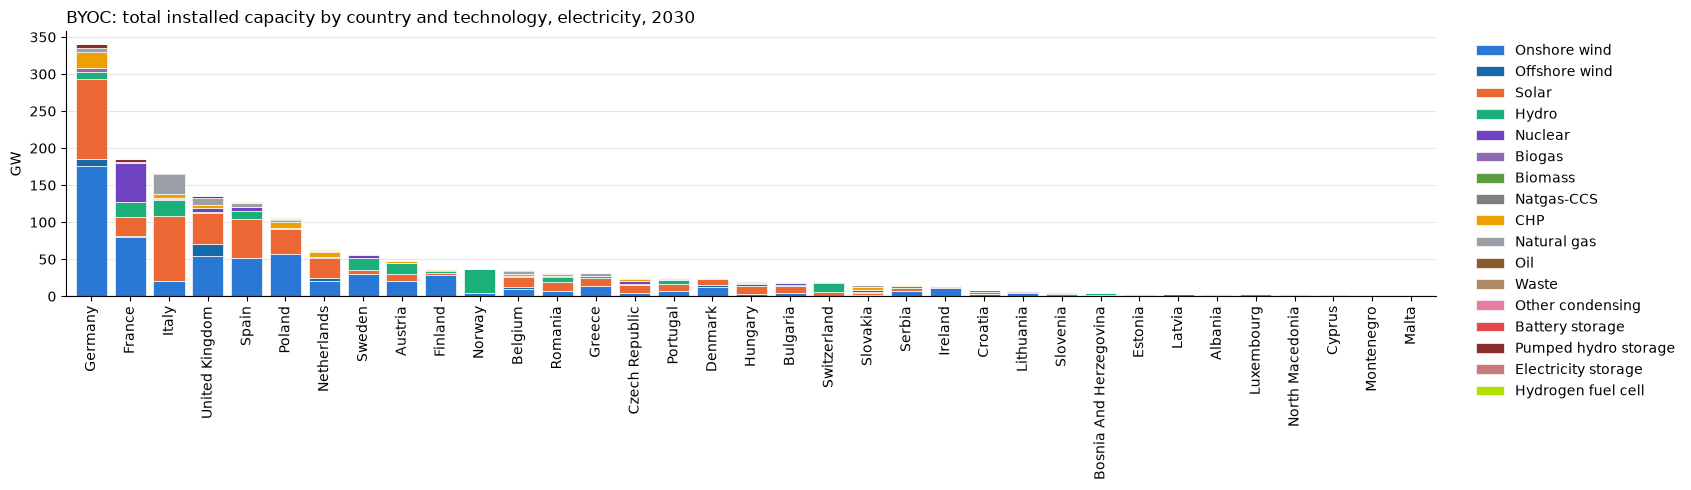

Group,Battery storage,Biogas,Biomass,CHP,Electricity storage,Hydro,Hydrogen fuel cell,Natgas-CCS,Natural gas,Nuclear,Offshore wind,Oil,Onshore wind,Other condensing,Pumped hydro storage,Solar,Waste,Total
"Total installed capacity, 2030 (GW)",,,,,,,,,,,,,,,,,,
GERMANY,0.00,5.58,0.00,21.37,0.01,8.97,0.07,0.00,4.90,0.00,9.22,0.00,175.61,0.00,5.85,109.02,0.04,340.60
FRANCE,0.00,0.00,0.00,0.01,0.00,21.00,0.00,0.00,0.00,52.81,1.48,0.00,80.00,0.00,4.77,25.00,0.68,185.76
ITALY,0.00,1.03,1.17,6.13,0.00,21.94,0.00,0.00,26.33,0.00,0.03,0.00,20.00,0.00,0.51,88.12,0.72,165.98
UNITED_KINGDOM,0.00,0.00,0.00,4.45,0.00,1.74,0.00,0.00,8.95,5.51,15.93,0.00,54.00,0.00,2.86,42.00,0.43,135.86
SPAIN,0.00,0.00,0.00,1.08,0.00,10.97,0.14,0.00,4.71,5.10,0.00,0.00,52.00,0.00,0.64,51.86,0.19,126.70
POLAND,0.00,0.36,0.00,8.63,0.00,0.95,0.25,0.00,2.60,0.00,0.00,0.00,57.24,0.00,1.77,33.23,0.00,105.05
NETHERLANDS,0.00,0.00,0.16,7.46,0.00,0.04,1.55,0.00,0.00,0.49,4.74,0.00,20.00,0.00,0.00,27.26,0.70,62.40
SWEDEN,0.00,0.00,0.00,1.27,0.00,16.32,0.00,0.00,0.00,3.54,0.22,0.00,30.43,0.00,0.00,5.00,0.00,56.77
AUSTRIA,0.00,0.06,0.00,3.34,0.00,14.15,0.00,0.00,0.00,0.00,0.00,0.00,20.50,0.00,0.00,10.20,0.02,48.27


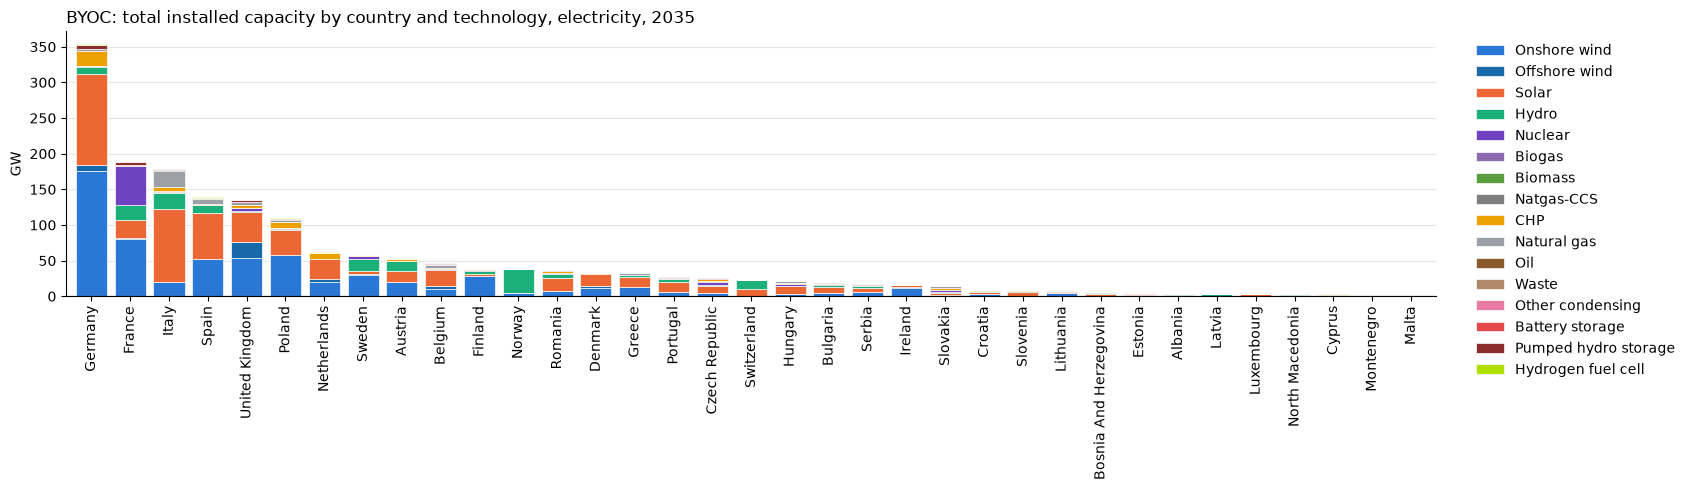

Group,Battery storage,Biogas,Biomass,CHP,Hydro,Hydrogen fuel cell,Natgas-CCS,Natural gas,Nuclear,Offshore wind,Oil,Onshore wind,Other condensing,Pumped hydro storage,Solar,Waste,Total
"Total installed capacity, 2035 (GW)",,,,,,,,,,,,,,,,,
GERMANY,0.00,2.54,0.00,20.56,8.97,1.60,0.00,2.39,0.00,9.22,0.00,175.61,0.0,5.85,127.16,0.03,353.91
FRANCE,0.00,0.35,0.00,0.80,21.00,0.00,0.00,0.00,54.70,1.48,0.00,80.00,0.0,4.77,25.00,0.68,188.78
ITALY,0.00,0.69,0.78,6.15,21.94,0.00,1.62,22.62,0.00,0.03,0.60,20.00,0.0,0.51,102.56,0.48,177.99
SPAIN,0.00,0.00,0.00,1.36,10.97,0.75,0.00,7.32,0.00,0.00,0.00,52.00,0.0,0.64,65.45,0.20,138.70
UNITED_KINGDOM,0.00,0.00,0.00,3.70,1.74,0.00,0.00,4.50,4.50,21.56,0.00,54.00,0.0,2.86,42.18,0.39,135.43
POLAND,0.00,0.36,0.00,7.73,0.95,0.62,0.00,2.60,2.22,0.00,0.00,57.24,0.0,1.77,35.60,0.00,109.11
NETHERLANDS,0.00,0.00,0.04,7.91,0.04,1.88,0.00,0.00,0.24,4.74,0.00,20.00,0.0,0.00,27.27,0.07,62.20
SWEDEN,0.00,0.00,0.00,1.71,16.32,0.00,0.00,0.00,4.80,0.22,0.00,30.43,0.0,0.00,5.00,0.00,58.48
AUSTRIA,0.00,0.04,0.00,3.12,14.15,0.00,0.00,0.00,0.00,0.00,0.04,20.50,0.0,0.00,14.60,0.00,52.46


In [36]:
# 4.1 Capacity of BYOC per country and technology group (GW)
COMMODITY = "ELECTRICITY"

def stacked_by_country(table, title, unit, ax=None):
    # One stacked bar per country (largest first), one segment per technology group
    t = table.loc[table.abs().sum(axis=1).sort_values(ascending=False).index]
    cols = [g for g in GROUP_COLORS if g in t.columns]
    ax = ax or plt.subplots(figsize=(max(10, 0.4 * len(t) + 3), 5))[1]
    t[cols].plot.bar(stacked=True, ax=ax, color=[GROUP_COLORS[c] for c in cols], width=0.8, edgecolor="#fcfcfb", linewidth=0.5)
    ax.set_xticklabels([clean_name(c) for c in t.index], rotation=90)
    ax.set_title(title, loc="left"); ax.set_xlabel(""); ax.set_ylabel(unit)
    ax.axhline(0, color="#52514e", linewidth=0.8)
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    return ax

cap = get(BYOC, "G_CAP_YCRAF").query("Commodity == @COMMODITY")
cap = cap.assign(Group=tech_group(cap))

def by_country_group(df, year):
    return df[df["Year"] == year].groupby(["Country", "Group"])["Value"].sum().unstack("Group").fillna(0)

for label, subset in [("New capacity (investments)", cap.query("Category == 'ENDOGENOUS'")),
                      ("Total installed capacity", cap)]:
    for year in YEARS:
        t = by_country_group(subset, year)
        if t.abs().to_numpy().sum() < 1e-6:
            continue
        stacked_by_country(t, f"BYOC: {label.lower()} by country and technology, {COMMODITY.lower()}, {year}", "GW")
        plt.tight_layout(); plt.show()
        display(t.assign(Total=t.sum(axis=1)).sort_values("Total", ascending=False).round(2).rename_axis(f"{label}, {year} (GW)"))

## 5. Generation of BYOC per country and technology type

Electricity production (TWh, `PRO_YCRAGF`) per country and technology group, same layout as section 4. Two views:

* **Total generation** of BYOC.
* **Change in generation** compared with `base_nodc` (BYOC - `base_nodc`): where the data-centre demand is produced, and which generation is displaced. BYOC has the same capacity of the reference system, so positive bars are mostly the new renewables.

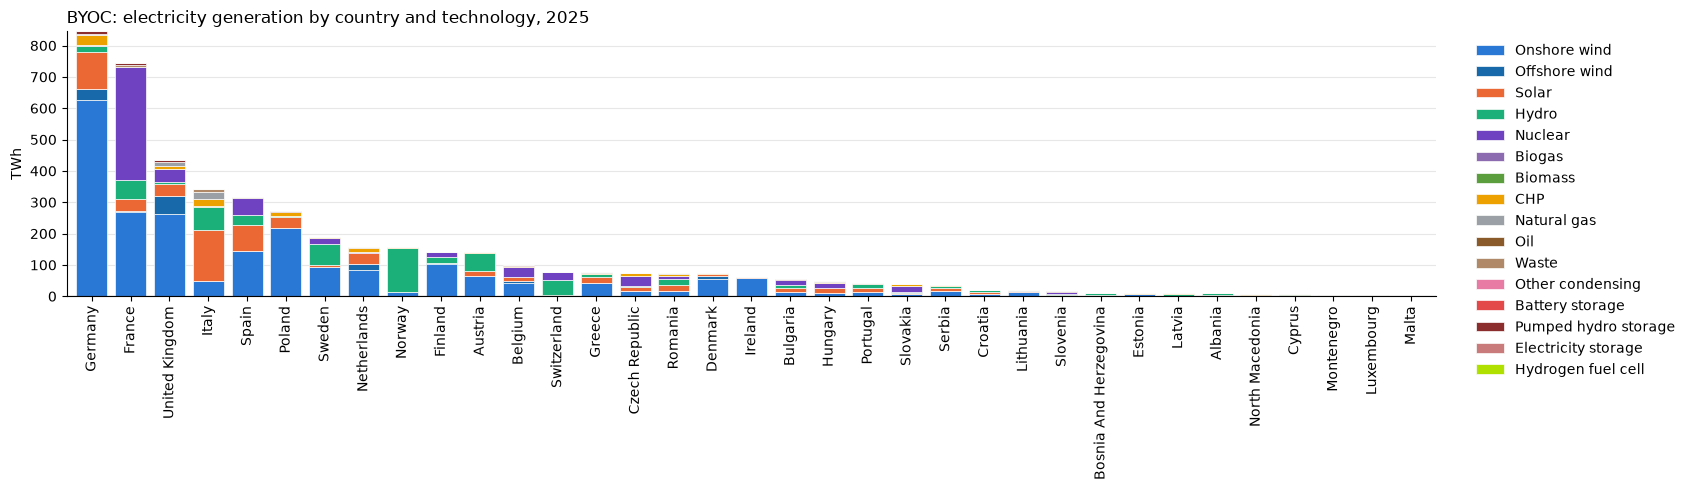

Group,Battery storage,Biogas,Biomass,CHP,Electricity storage,Hydro,Hydrogen fuel cell,Natural gas,Nuclear,Offshore wind,Oil,Onshore wind,Other condensing,Pumped hydro storage,Solar,Waste,Total
"Generation, 2025 (TWh)",,,,,,,,,,,,,,,,,
GERMANY,0.0,1.45,0.00,32.72,0.0,18.45,0.0,3.37,0.00,35.52,0.0,625.41,0.00,8.22,119.88,0.34,845.35
FRANCE,0.0,0.00,0.00,0.07,0.0,61.48,0.0,0.00,362.06,4.60,0.0,268.99,0.00,5.97,35.35,5.65,744.17
UNITED_KINGDOM,0.0,0.00,0.00,10.35,0.0,5.24,0.0,9.96,43.54,55.90,0.0,264.06,0.00,4.44,37.85,2.60,433.94
ITALY,0.0,0.16,4.16,22.48,0.0,71.90,0.0,21.73,0.00,0.07,0.0,48.46,0.00,1.03,163.70,8.05,341.74
SPAIN,0.0,0.00,0.00,1.01,0.0,33.00,0.0,0.37,53.50,0.00,0.0,144.28,0.00,1.15,82.47,1.45,317.23
POLAND,0.0,0.10,0.00,12.02,0.0,2.29,0.0,0.47,0.00,0.00,0.0,219.21,0.00,1.98,34.84,0.00,270.90
SWEDEN,0.0,0.00,0.00,3.40,0.0,68.53,0.0,0.00,18.28,0.68,0.0,93.03,0.00,0.00,5.84,0.00,189.76
NETHERLANDS,0.0,0.00,0.46,12.15,0.0,0.16,0.0,0.79,3.63,18.00,0.0,84.77,0.00,0.00,34.53,3.89,158.38
NORWAY,0.0,0.00,0.00,0.28,0.0,141.95,0.0,0.00,0.00,0.32,0.0,13.22,0.00,0.00,0.02,0.00,155.79


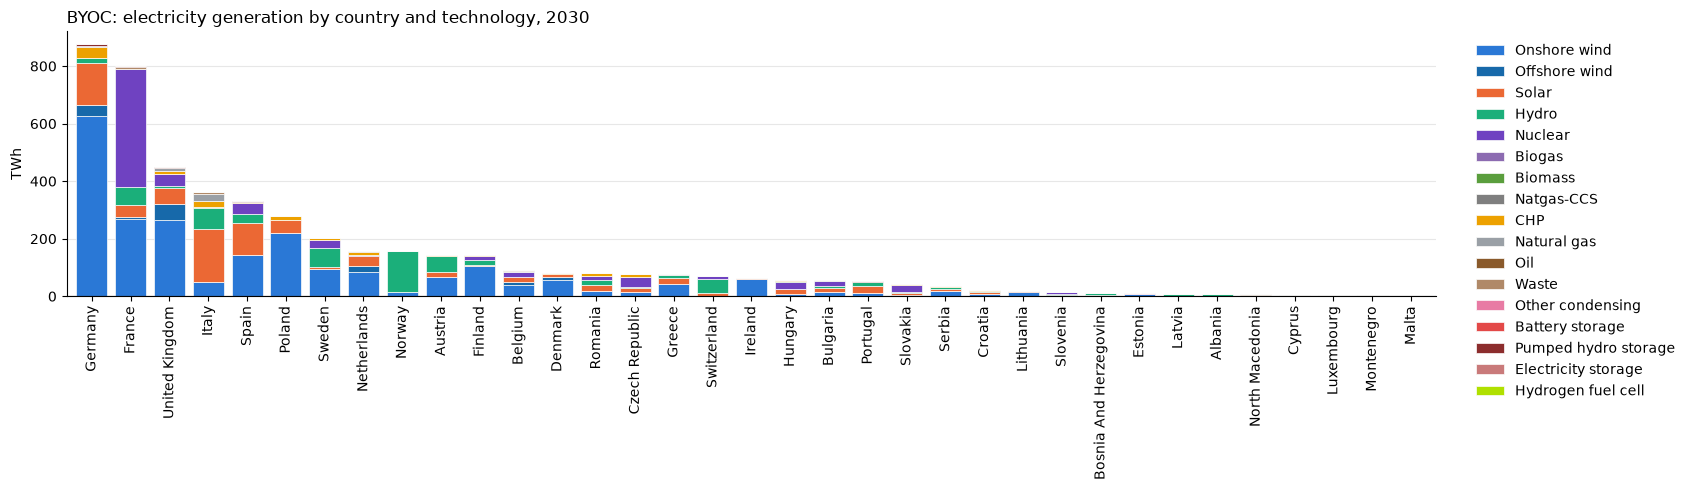

Group,Battery storage,Biogas,Biomass,CHP,Electricity storage,Hydro,Hydrogen fuel cell,Natgas-CCS,Natural gas,Nuclear,Offshore wind,Oil,Onshore wind,Other condensing,Pumped hydro storage,Solar,Waste,Total
"Generation, 2030 (TWh)",,,,,,,,,,,,,,,,,,
GERMANY,0.00,1.00,0.00,37.53,0.0,18.45,0.04,0.00,3.38,0.00,37.37,0.00,628.19,0.00,6.30,144.27,0.34,876.88
FRANCE,0.00,0.00,0.00,0.00,0.0,61.48,0.00,0.00,0.00,410.63,4.70,0.00,270.03,0.00,3.72,42.98,5.65,799.20
UNITED_KINGDOM,0.00,0.00,0.00,12.32,0.0,5.24,0.00,0.00,7.71,41.15,57.74,0.00,264.35,0.00,3.21,55.61,2.40,449.73
ITALY,0.00,0.08,3.03,22.78,0.0,72.10,0.00,0.00,23.59,0.00,0.07,0.00,48.35,0.00,1.05,185.38,6.04,362.49
SPAIN,0.00,0.00,0.00,1.28,0.0,33.00,0.02,0.00,0.70,38.71,0.00,0.00,143.22,0.00,1.16,109.96,1.45,329.50
POLAND,0.00,0.08,0.00,11.11,0.0,2.29,0.12,0.00,0.46,0.00,0.00,0.00,220.59,0.00,1.83,43.61,0.00,280.10
SWEDEN,0.00,0.00,0.00,3.79,0.0,68.53,0.00,0.00,0.00,28.36,0.71,0.00,93.72,0.00,0.00,5.84,0.00,200.94
NETHERLANDS,0.00,0.00,0.24,9.87,0.0,0.16,1.13,0.00,0.00,3.84,18.71,0.00,85.89,0.00,0.00,34.53,3.76,158.13
NORWAY,0.00,0.00,0.00,0.18,0.0,141.95,0.00,0.00,0.00,0.00,0.34,0.00,13.38,0.00,0.00,0.02,0.00,155.86


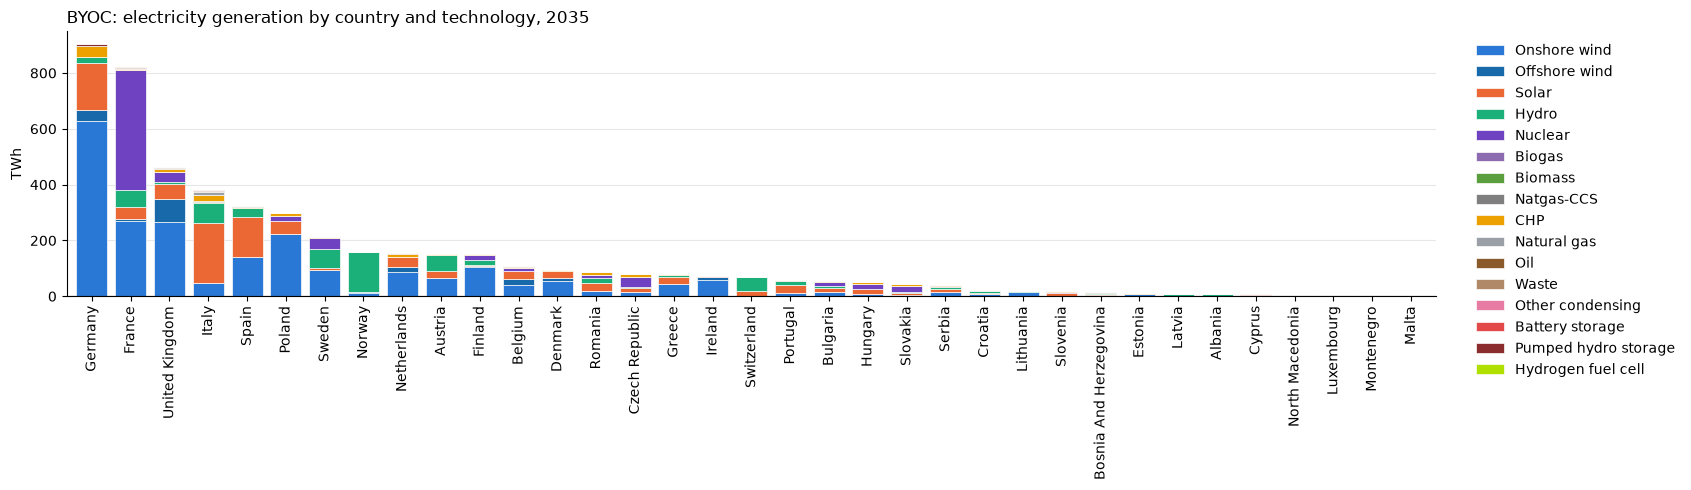

Group,Battery storage,Biogas,Biomass,CHP,Hydro,Hydrogen fuel cell,Natgas-CCS,Natural gas,Nuclear,Offshore wind,Oil,Onshore wind,Other condensing,Pumped hydro storage,Solar,Waste,Total
"Generation, 2035 (TWh)",,,,,,,,,,,,,,,,,
GERMANY,0.00,0.57,0.00,39.18,18.45,1.17,0.00,1.27,0.00,37.38,0.00,628.72,0.00,5.97,171.06,0.28,904.04
FRANCE,0.00,0.01,0.00,1.56,61.48,0.00,0.00,0.00,430.69,4.70,0.00,271.22,0.00,3.15,42.98,5.65,821.45
UNITED_KINGDOM,0.00,0.00,0.00,12.74,5.24,0.00,0.00,3.22,35.28,83.74,0.00,264.35,0.00,2.28,55.83,2.23,464.91
ITALY,0.00,0.04,1.73,20.73,71.86,0.00,4.53,12.26,0.00,0.07,0.02,48.25,0.00,1.02,215.01,4.01,379.53
SPAIN,0.00,0.00,0.00,3.80,33.00,0.16,0.00,1.45,0.00,0.00,0.00,141.77,0.00,1.33,142.06,1.45,325.03
POLAND,0.00,0.08,0.00,8.71,2.29,0.39,0.00,0.31,17.32,0.00,0.00,221.35,0.00,1.88,47.00,0.00,299.34
SWEDEN,0.00,0.00,0.00,6.50,68.53,0.00,0.00,0.00,38.69,0.71,0.00,93.72,0.00,0.00,5.84,0.00,213.98
NORWAY,0.00,0.00,0.00,0.34,141.95,0.00,0.00,0.00,0.00,0.34,0.00,13.38,0.00,0.00,1.62,0.00,157.62
NETHERLANDS,0.00,0.00,0.06,11.43,0.16,1.70,0.00,0.00,1.92,18.71,0.00,85.91,0.00,0.00,34.54,0.62,155.06


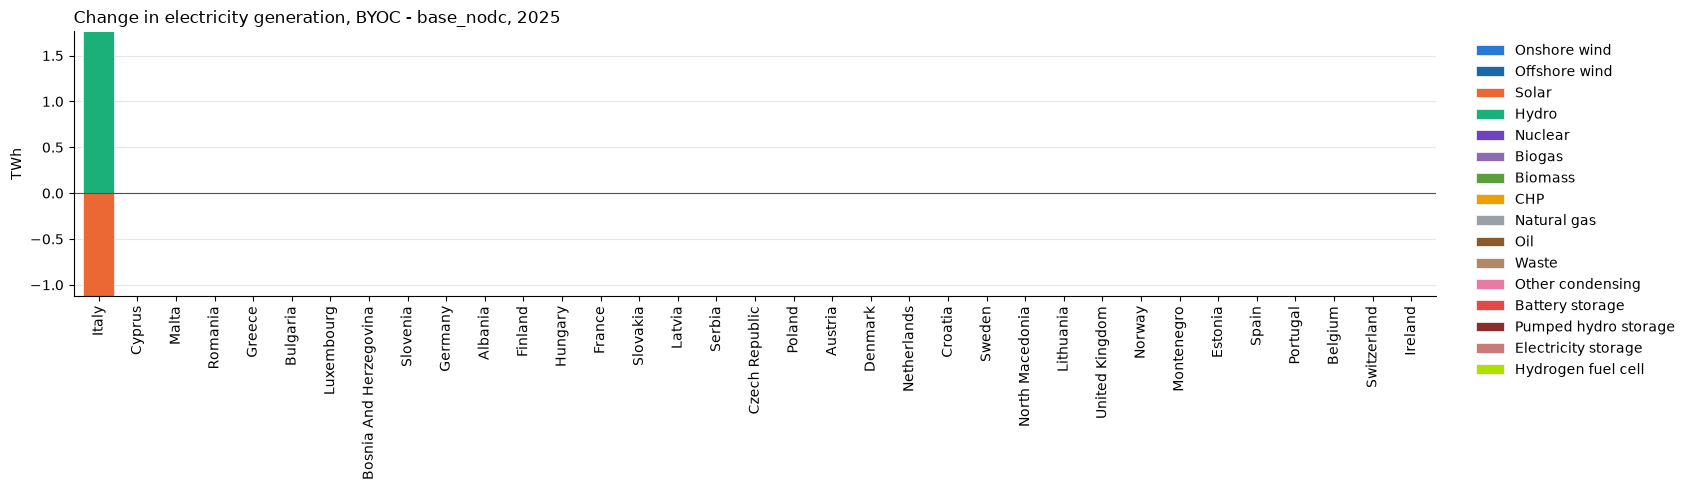

Group,Battery storage,Biogas,Biomass,CHP,Electricity storage,Hydro,Hydrogen fuel cell,Natural gas,Nuclear,Offshore wind,Oil,Onshore wind,Other condensing,Pumped hydro storage,Solar,Waste,Total
"Change in generation, 2025 (TWh)",,,,,,,,,,,,,,,,,
ITALY,0.0,-0.0,0.0,-0.0,0.0,1.76,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,-1.12,0.0,0.64
CYPRUS,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.01,0.0,0.01
MALTA,0.0,0.0,0.0,0.0,0.0,0.00,0.0,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00
BULGARIA,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0,0.00,0.0,0.00
LUXEMBOURG,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.00,0.0,0.00
BOSNIA_AND_HERZEGOVINA,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.00,0.0,0.00
SLOVENIA,0.0,0.0,0.0,0.0,0.0,0.00,0.0,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00
FINLAND,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00
ALBANIA,0.0,0.0,0.0,0.0,0.0,-0.00,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.00,0.0,0.00


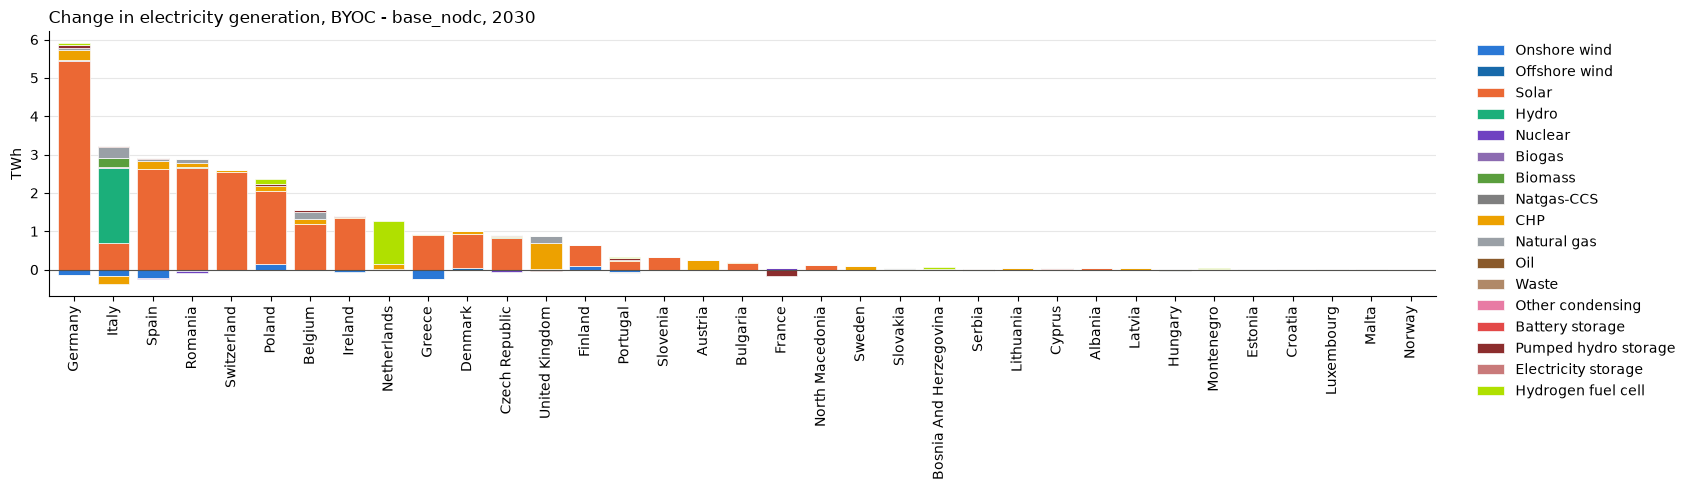

Group,Battery storage,Biogas,Biomass,CHP,Electricity storage,Hydro,Hydrogen fuel cell,Natgas-CCS,Natural gas,Nuclear,Offshore wind,Oil,Onshore wind,Other condensing,Pumped hydro storage,Solar,Waste,Total
"Change in generation, 2030 (TWh)",,,,,,,,,,,,,,,,,,
GERMANY,0.00,0.01,0.00,0.27,0.0,0.00,0.04,0.00,0.06,0.00,-0.01,0.0,-0.13,0.0,0.07,5.45,0.0,5.76
ITALY,0.00,0.01,0.24,-0.21,0.0,1.95,0.00,0.00,0.29,0.00,-0.00,0.0,-0.17,0.0,0.02,0.71,0.0,2.84
ROMANIA,0.00,0.00,0.00,0.12,0.0,-0.00,0.00,0.00,0.11,-0.07,0.00,0.0,-0.02,0.0,0.00,2.66,0.0,2.80
SPAIN,0.00,0.00,0.00,0.22,0.0,0.00,0.02,0.00,0.03,-0.01,-0.00,0.0,-0.22,0.0,0.02,2.62,0.0,2.69
SWITZERLAND,0.00,0.00,0.00,0.06,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.0,0.00,2.54,0.0,2.61
POLAND,0.00,0.00,0.00,0.13,0.0,0.00,0.12,0.00,-0.00,0.00,0.00,0.0,0.14,0.0,0.05,1.91,0.0,2.36
BELGIUM,0.00,0.00,0.00,0.12,0.0,0.00,0.00,0.00,0.19,0.00,0.00,0.0,0.00,0.0,0.04,1.20,-0.0,1.55
IRELAND,0.00,0.00,0.00,0.03,0.0,0.00,0.02,0.00,0.00,0.00,0.00,0.0,-0.05,0.0,0.01,1.35,0.0,1.35
NETHERLANDS,0.00,0.00,0.01,0.13,0.0,0.00,1.13,0.00,0.00,0.00,0.00,0.0,-0.01,0.0,0.00,0.00,-0.0,1.27


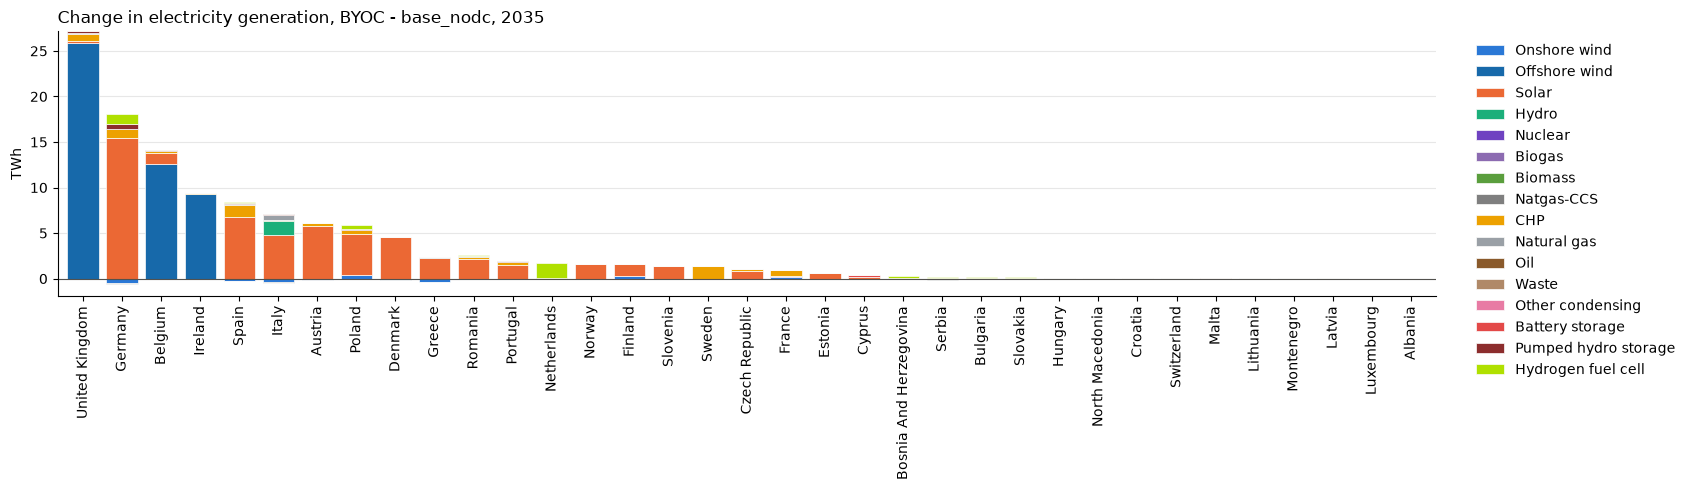

Group,Battery storage,Biogas,Biomass,CHP,Hydro,Hydrogen fuel cell,Natgas-CCS,Natural gas,Nuclear,Offshore wind,Oil,Onshore wind,Other condensing,Pumped hydro storage,Solar,Waste,Total
"Change in generation, 2035 (TWh)",,,,,,,,,,,,,,,,,
UNITED_KINGDOM,0.00,0.00,0.00,0.70,0.00,0.00,0.00,0.10,0.00,25.92,0.0,0.00,0.0,0.21,0.22,-0.00,27.15
GERMANY,0.00,0.01,0.00,1.00,0.00,1.17,0.00,-0.04,0.00,0.00,0.0,-0.51,0.0,0.49,15.46,0.00,17.58
BELGIUM,0.00,0.00,0.00,0.15,0.00,0.00,0.00,-0.02,0.00,12.63,0.0,0.00,0.0,0.13,1.20,-0.00,14.09
IRELAND,0.00,0.00,0.00,0.02,0.00,0.01,0.00,0.00,0.00,9.32,0.0,0.00,0.0,0.00,0.02,0.00,9.38
SPAIN,0.00,0.00,0.00,1.27,-0.00,0.16,0.00,0.15,0.00,-0.00,0.0,-0.31,0.0,0.03,6.79,0.00,8.11
ITALY,0.00,0.00,0.04,0.06,1.53,0.00,-0.04,0.51,0.00,-0.00,0.0,-0.41,0.0,0.10,4.81,-0.02,6.59
AUSTRIA,0.00,0.00,0.00,0.30,0.00,0.00,0.00,0.00,0.00,0.00,0.0,-0.13,0.0,0.00,5.82,-0.00,5.99
POLAND,0.00,-0.01,0.00,0.46,0.00,0.39,0.00,-0.06,0.00,0.00,0.0,0.37,0.0,0.12,4.54,0.00,5.82
DENMARK,0.00,0.00,0.00,0.05,0.00,0.00,0.00,-0.00,0.00,-0.12,0.0,0.00,0.0,0.00,4.54,0.00,4.46


In [37]:
# 5.1 Generation of BYOC per country and technology group (TWh)
def generation(run):
    t = get(run, "PRO_YCRAGF").query("Commodity == @COMMODITY")
    return t.assign(Group=tech_group(t))

gen = generation(BYOC)
gen_ref = generation(REFERENCE)

for year in YEARS:
    t = by_country_group(gen, year)
    stacked_by_country(t, f"BYOC: {COMMODITY.lower()} generation by country and technology, {year}", "TWh")
    plt.tight_layout(); plt.show()
    display(t.assign(Total=t.sum(axis=1)).sort_values("Total", ascending=False).round(2).rename_axis(f"Generation, {year} (TWh)"))

for year in YEARS:
    d = by_country_group(gen, year).sub(by_country_group(gen_ref, year), fill_value=0).fillna(0)
    if d.abs().to_numpy().sum() < 1e-3:
        continue                                                              # no difference (years without extra load)
    stacked_by_country(d, f"Change in {COMMODITY.lower()} generation, BYOC - {REFERENCE}, {year}", "TWh")
    plt.tight_layout(); plt.show()
    display(d.assign(Total=d.sum(axis=1)).sort_values("Total", ascending=False).round(2).rename_axis(f"Change in generation, {year} (TWh)"))

## 6. Change in marginal electricity price per country, BYOC vs `base_dc`

Change (BYOC - `base_dc`, Money/MWh) in the marginal cost of electricity per country in `PRICE_YEAR` (default: last year). `EL_PRICE_YCR` (time-averaged marginal cost of the electricity balance per region) is averaged over the regions of a country, weighted by the annual electricity demand of each region in that run. Red = more expensive in BYOC, blue = cheaper. The labels give the change per country; the table below the map lists the prices.

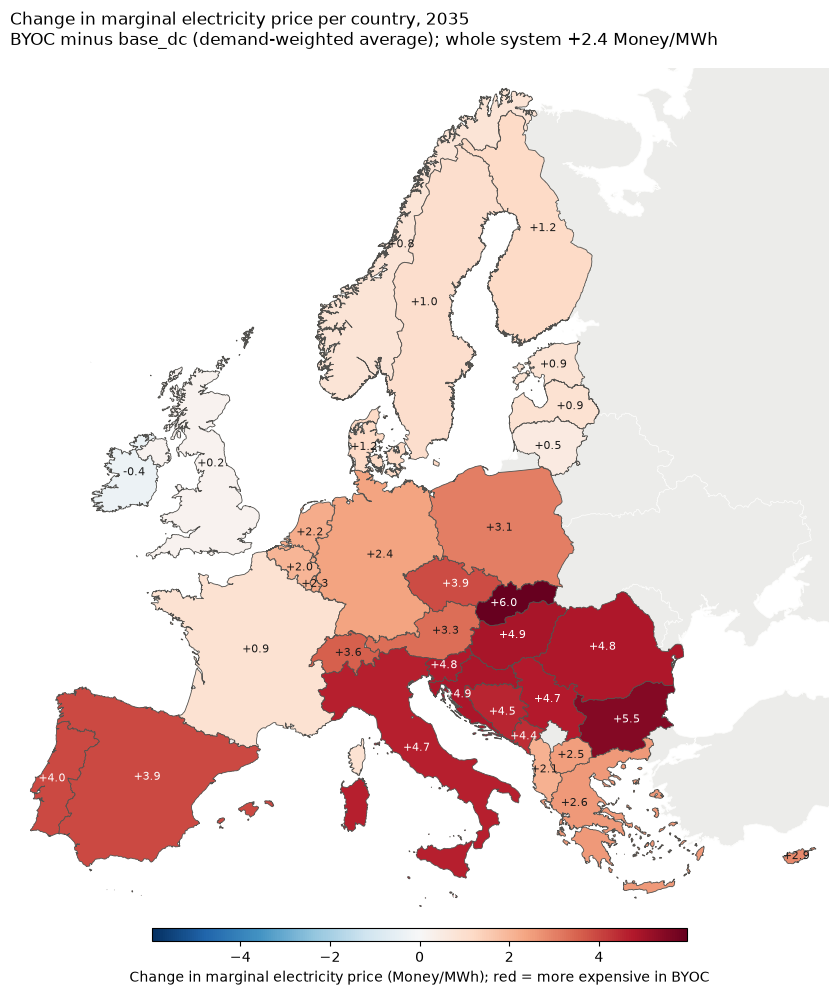

,base_dc,BYOC,Change (Money/MWh),Change (%)
"Marginal electricity price, 2035 (Money/MWh)",,,,
SLOVAKIA,47.05,53.02,5.97,12.68
BULGARIA,46.64,52.12,5.48,11.75
HUNGARY,48.55,53.48,4.93,10.16
CROATIA,48.30,53.20,4.89,10.13
ROMANIA,47.88,52.69,4.82,10.06
SLOVENIA,48.33,53.10,4.77,9.87
SERBIA,48.01,52.74,4.73,9.86
ITALY,46.63,51.29,4.65,9.98
BOSNIA_AND_HERZEGOVINA,48.31,52.86,4.54,9.41


In [38]:
# 6.1 Map of the change in the demand-weighted marginal electricity price per country (Money/MWh)
import geopandas as gpd
import pybalmorel
from matplotlib.colors import TwoSlopeNorm

PRICE_YEAR = "2035" if "2035" in YEARS else YEARS[-1]

def price_by_country(run):
    # Demand-weighted average of EL_PRICE_YCR over the regions of each country in PRICE_YEAR
    price = get(run, "EL_PRICE_YCR").query("Category == 'AVERAGE' and Year == @PRICE_YEAR").set_index(["Country", "Region"])["Value"]
    demand = get(run, "EL_DEMAND_YCR").query("Year == @PRICE_YEAR").groupby(["Country", "Region"])["Value"].sum()
    t = pd.concat({"P": price, "D": demand}, axis=1).dropna()
    return (t["P"] * t["D"]).groupby("Country").sum() / t["D"].groupby("Country").sum()

price_cmp = pd.DataFrame({BASE_DC: price_by_country(BASE_DC), BYOC: price_by_country(BYOC)}).dropna()
price_cmp["Change (Money/MWh)"] = price_cmp[BYOC] - price_cmp[BASE_DC]
price_cmp["Change (%)"] = price_cmp["Change (Money/MWh)"] / price_cmp[BASE_DC] * 100
price_cmp = price_cmp.sort_values("Change (Money/MWh)")

# Country polygons = the region polygons of pybalmorel's geofile, merged per country (region -> country from the results)
GEO_DIR = Path(pybalmorel.__file__).parent / "geofiles"
polygons = gpd.read_file(GEO_DIR / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs("EPSG:3035")
region_country = get(BYOC, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
polygons["Country"] = polygons["id"].map(region_country)
countries = polygons.dropna(subset=["Country"]).dissolve(by="Country").join(price_cmp)

fig, ax = plt.subplots(figsize=(11, 11))
polygons[polygons["Country"].isna()].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)      # outside the model
lim = max(price_cmp["Change (Money/MWh)"].abs().max(), 1e-6)
norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
countries.plot(ax=ax, column="Change (Money/MWh)", cmap="RdBu_r", norm=norm, edgecolor="#52514e", linewidth=0.6,
               missing_kwds={"color": "#ececea"})
# Label every country with its change; the label sits on the largest part of the country (mainland, not islands)
for name, row in countries.dropna(subset=["Change (Money/MWh)"]).iterrows():
    part = max(getattr(row.geometry, "geoms", [row.geometry]), key=lambda g: g.area)
    point = part.representative_point()
    ax.annotate(f"{row['Change (Money/MWh)']:+.1f}", (point.x, point.y), ha="center", va="center", fontsize=8,
                color="white" if abs(row["Change (Money/MWh)"]) > 0.6 * lim else "#1a1a1a")
minx, miny, maxx, maxy = countries.geometry.apply(lambda g: max(getattr(g, "geoms", [g]), key=lambda x: x.area)).total_bounds
ax.set_xlim(minx - 1e5, maxx + 1e5); ax.set_ylim(miny - 1e5, maxy + 1e5)      # zoom on the mainland of the modelled countries
ax.set_axis_off()
system = marginal_cost(BYOC)[PRICE_YEAR] - marginal_cost(BASE_DC)[PRICE_YEAR]
ax.set_title(f"Change in marginal electricity price per country, {PRICE_YEAR}\n{BYOC} minus {BASE_DC} (demand-weighted average); whole system {system:+.1f} Money/MWh", loc="left")
fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=norm), ax=ax, orientation="horizontal", shrink=0.5, pad=0.01, aspect=40,
             label="Change in marginal electricity price (Money/MWh); red = more expensive in BYOC")
plt.tight_layout(); plt.show()

display(price_cmp.sort_values("Change (Money/MWh)", ascending=False).round(2).rename_axis(f"Marginal electricity price, {PRICE_YEAR} (Money/MWh)"))

## 7. Map: change in marginal price with the change in generation per fuel type

The colours are the change in marginal electricity price per country of section 6 (BYOC - `base_dc`, red = more expensive in BYOC). On top, one **pie chart per country** shows how the electricity generation (`PRO_YCRAGF`, TWh) changes per fuel type between `base_dc` and BYOC in `PRICE_YEAR`.

* A pie cannot show a negative value, so the slices are the **absolute** change per fuel: the angle of a slice is its share of the total change of the country. **Hatched slices are decreases**, plain slices are increases.
* The **area of the pie** is proportional to the total absolute change in generation of the country (reference circle in the legend).
* Fuels are grouped (wood, straw and bio-oil as biomass; municipal waste and waste heat as waste; wind split in onshore and offshore; electricity storage discharge as its own group).

The cell uses the map layers and the price change of 6.1, so run that cell first.

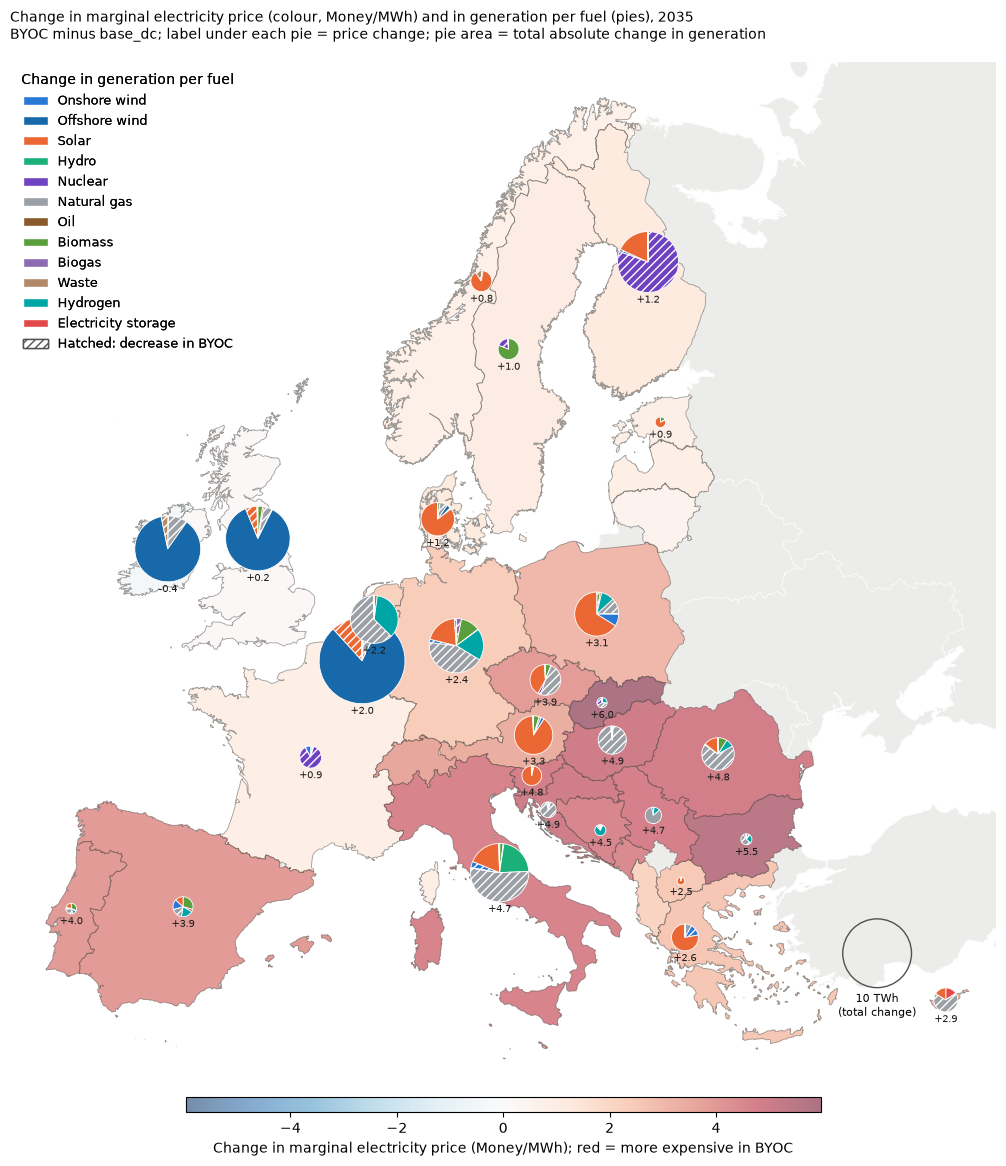

Group,Biogas,Biomass,Electricity storage,Hydro,Hydrogen,Natural gas,Nuclear,Offshore wind,Oil,Onshore wind,Other,Solar,Waste,Total
"Change in generation, 2035 (TWh)",,,,,,,,,,,,,,
BELGIUM,0.00,0.12,0.08,0.00,0.00,-0.88,-0.04,12.63,0.00,0.00,0.0,-1.82,0.01,10.10
UNITED_KINGDOM,0.00,0.21,0.07,0.00,0.00,-0.35,-0.03,7.61,0.00,0.00,0.0,-0.51,0.04,7.04
IRELAND,0.00,0.02,0.00,0.00,0.01,-0.86,0.00,7.99,0.00,0.00,0.0,0.00,-0.30,6.85
AUSTRIA,0.00,0.15,0.00,0.00,0.00,0.05,0.00,0.00,0.00,-0.08,0.0,2.82,0.03,2.97
POLAND,-0.01,-0.10,-0.05,0.00,0.39,-0.46,0.03,0.00,0.00,0.36,0.0,2.71,0.00,2.88
DENMARK,0.00,0.05,0.00,0.00,-0.00,-0.17,0.00,-0.12,0.00,0.00,0.0,2.02,0.01,1.79
GREECE,0.00,0.01,0.00,0.00,0.00,0.11,0.00,0.00,0.00,-0.21,0.0,1.19,0.00,1.10
SLOVENIA,0.00,-0.00,0.00,0.00,0.00,0.02,-0.00,0.00,0.00,-0.00,0.0,0.79,-0.00,0.80
NORWAY,0.00,0.03,0.00,0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.82,-0.09,0.76


In [39]:
# 7.1 Map of the change in marginal price, overlayed by pie charts of the change in generation per fuel (BYOC - base_dc, TWh)
from matplotlib.patches import Patch, Circle

FUEL_GROUP = {"WATER": "Hydro", "NUCLEAR": "Nuclear", "NATGAS": "Natural gas", "SUN": "Solar", "HYDROGEN": "Hydrogen",
              "COAL": "Coal & lignite", "LIGNITE": "Coal & lignite", "PEAT": "Coal & lignite", "SHALE": "Coal & lignite", "COKE": "Coal & lignite",
              "FUELOIL": "Oil", "LIGHTOIL": "Oil", "HEAVYFUELOIL": "Oil",
              "WOOD": "Biomass", "WOODCHIPS": "Biomass", "WOODPELLETS": "Biomass", "WOODWASTE": "Biomass", "STRAW": "Biomass", "BIOOIL": "Biomass",
              "BIOGAS": "Biogas", "MUNIWASTE": "Waste", "HAZARDOUSWASTE": "Waste", "WASTEHEAT": "Waste",
              "ELECTRIC": "Electricity storage"}                    # anything else (HEAT, DUMMY, ...) is "Other"
FUEL_COLORS = {"Onshore wind": "#2a78d6", "Offshore wind": "#1769aa", "Solar": "#eb6834", "Hydro": "#1baf7a", "Nuclear": "#6f42c1",
               "Natural gas": "#9aa0a6", "Coal & lignite": "#3b3b3b", "Oil": "#8a5a2b", "Biomass": "#5a9e3d", "Biogas": "#8c6bb1",
               "Waste": "#b08968", "Hydrogen": "#00a6a6", "Electricity storage": "#e34948", "Other": "#d9d9d4"}

def generation_by_fuel(run):
    # Electricity generation per country and fuel group in PRICE_YEAR (TWh)
    t = get(run, "PRO_YCRAGF").query("Commodity == 'ELECTRICITY' and Year == @PRICE_YEAR")
    group = t["Fuel"].map(FUEL_GROUP).fillna("Other")
    group = group.mask(t["Fuel"].eq("WIND") & t["Technology"].str.upper().str.contains("OFF"), "Offshore wind")
    group = group.mask(t["Fuel"].eq("WIND") & ~t["Technology"].str.upper().str.contains("OFF"), "Onshore wind")
    return t.assign(Group=group).groupby(["Country", "Group"])["Value"].sum()

gen_change = generation_by_fuel(BYOC).sub(generation_by_fuel(BASE_DC), fill_value=0).unstack("Group").fillna(0)
gen_change = gen_change.loc[gen_change.index.isin(countries.dropna(subset=["Change (Money/MWh)"]).index)]
total_change = gen_change.abs().sum(axis=1)

PIE_MIN = 0.1                                          # TWh: countries with a smaller total change get no pie
R_MAX = 1.8e5                                          # radius (m, map units) of the pie of the country with the largest change
radius = lambda tot: R_MAX * np.sqrt(tot / total_change.max())

fig, ax = plt.subplots(figsize=(13, 13))
polygons[polygons["Country"].isna()].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)
lim = max(price_cmp["Change (Money/MWh)"].abs().max(), 1e-6)
norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
countries.plot(ax=ax, column="Change (Money/MWh)", cmap="RdBu_r", norm=norm, alpha=0.55, edgecolor="#52514e", linewidth=0.6,
               missing_kwds={"color": "#ececea"})
ax.set_aspect("equal")                                 # pies are drawn in map units, so they stay round

for country, row in countries.dropna(subset=["Change (Money/MWh)"]).iterrows():
    if country not in gen_change.index or total_change[country] < PIE_MIN:
        continue
    part = max(getattr(row.geometry, "geoms", [row.geometry]), key=lambda g: g.area)
    point = part.representative_point()
    values = gen_change.loc[country]
    values = values[values.abs() > 1e-6]
    wedges, _ = ax.pie(values.abs(), colors=[FUEL_COLORS[g] for g in values.index], center=(point.x, point.y),
                       radius=radius(total_change[country]), startangle=90, counterclock=False, frame=True,
                       wedgeprops={"edgecolor": "white", "linewidth": 0.6})
    for wedge, v in zip(wedges, values):
        if v < 0:
            wedge.set_hatch("////")                     # hatched = generation decreases in BYOC
    ax.annotate(f"{row['Change (Money/MWh)']:+.1f}", (point.x, point.y - radius(total_change[country])), xytext=(0, -2), textcoords="offset points",
                ha="center", va="top", fontsize=7, color="#1a1a1a")

minx, miny, maxx, maxy = countries.geometry.apply(lambda g: max(getattr(g, "geoms", [g]), key=lambda x: x.area)).total_bounds
ax.set_xlim(minx - 1.5e5, maxx + 1.5e5); ax.set_ylim(miny - 1.5e5, maxy + 1.5e5)
ax.set_axis_off()

used = [g for g in FUEL_COLORS if g in gen_change.columns and gen_change[g].abs().max() > 1e-6]
handles = [Patch(facecolor=FUEL_COLORS[g], edgecolor="white", label=g) for g in used]
handles += [Patch(facecolor="#ffffff", edgecolor="#52514e", hatch="////", label="Hatched: decrease in BYOC")]
legend = ax.legend(handles=handles, title="Change in generation per fuel", loc="upper left", frameon=False, fontsize=9)
ax.add_artist(legend)
ref = 10 ** np.floor(np.log10(total_change.max()))      # reference circle: round TWh value below the largest change
ax.add_patch(Circle((maxx - 3.5e5, miny + 4e5), radius(ref), facecolor="none", edgecolor="#52514e", linewidth=1))
ax.annotate(f"{ref:g} TWh\n(total change)", (maxx - 3.5e5, miny + 4e5 - radius(ref)), xytext=(0, -3), textcoords="offset points",
            ha="center", va="top", fontsize=8)
ax.set_title(f"Change in marginal electricity price (colour, Money/MWh) and in generation per fuel (pies), {PRICE_YEAR}\n{BYOC} minus {BASE_DC}; "
             f"label under each pie = price change; pie area = total absolute change in generation", loc="left", fontsize=10)
fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=norm), ax=ax, orientation="horizontal", shrink=0.5, pad=0.01, aspect=40, alpha=0.55,
             label="Change in marginal electricity price (Money/MWh); red = more expensive in BYOC")
plt.tight_layout(); plt.show()

display(gen_change.assign(Total=gen_change.sum(axis=1)).sort_values("Total", ascending=False).round(2).rename_axis(f"Change in generation, {PRICE_YEAR} (TWh)"))

## 8. What replaces the lost generation in the hours when the price rises?

For the `TOP_N` countries with the highest increase in marginal electricity price (section 6), this section looks at the **time slices** (hours) of `PRICE_YEAR` and asks which supply takes over in BYOC compared with `base_dc`. The slices are matched one to one between the two runs and every region-hour is put in a band by its price change (BYOC - `base_dc`): small (<= 5 Money/MWh), moderate (5 - 20) and large (> 20).

Per band and country the bars show the **average change in electricity supply per region-hour (MWh)**: generation per technology and fuel, and net imports (= change in total electricity demand - change in generation, so imports include the effect of lower or higher endogenous demand). Bars above zero are supply that BYOC adds, bars below zero supply that it loses. The black diamond is the change in total electricity demand, which equals the sum of all bars.

This is an **operational** view of the "next cheapest option": it shows what is dispatched more when the price rises. It does not prove which unit sets the price in each hour: hydro reservoirs and CHP are partially loaded in almost every hour, so the marginal unit cannot be read from the dispatch alone.

Countries with the highest price increase: Slovakia, Bulgaria, Hungary, Croatia, Romania


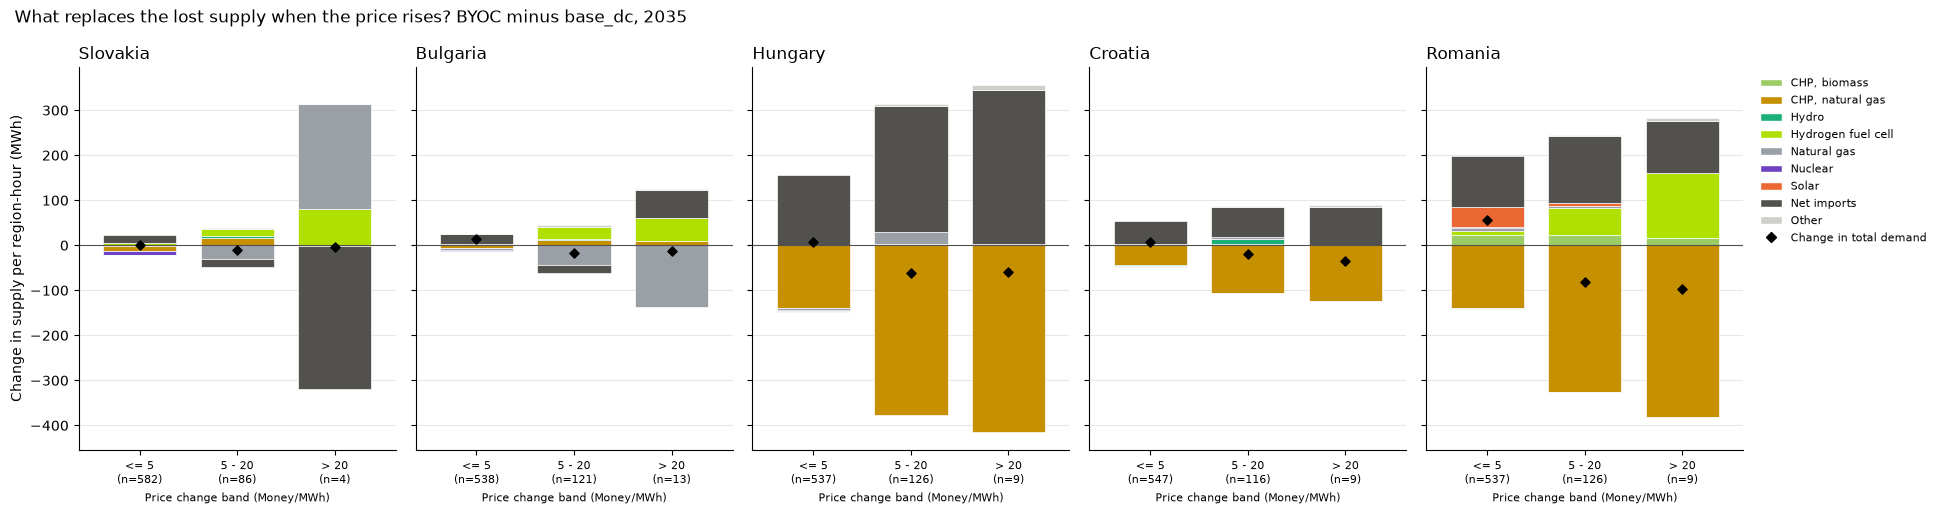

CHP, biomass  CHP, natural gas  Hydro  \
Country  Price change band                                          
Slovakia <= 5                       -0.6             -11.4   -0.7   
         5 - 20                      0.8              15.1    4.8   
         > 20                       -0.4              -2.1    0.0   
Bulgaria <= 5                        1.5              -5.6   -0.3   
         5 - 20                      1.7              10.8    1.5   
         > 20                        0.0              10.6    0.0   
Hungary  <= 5                        1.3            -138.8   -0.2   
         5 - 20                      1.7            -376.4    1.0   
         > 20                        2.2            -415.6    0.0   
Croatia  <= 5                        1.7             -43.6   -2.6   
         5 - 20                      1.9            -107.0   12.3   
         > 20                        0.2            -124.5    0.0   
Romania  <= 5                       23.0            -139.1   -0.1   
         5 - 20                     22.2            -326.2    0.6   
         > 20                       16.5            -380.2    0.0   

                            Hydrogen fuel cell  Natural gas  Nuclear  Solar  \
Country  Price change band                                                    
Slovakia <= 5                              4.1          0.0     -9.2   -0.0   
         5 - 20                           14.8        -29.9      0.0   -0.0   
         > 20                             79.5        235.1      0.0    0.0   
Bulgaria <= 5                              2.4         -3.8     -2.9    0.0   
         5 - 20                           26.1        -43.4      0.0    0.0   
         > 20                             49.1       -137.6      0.0    0.0   
Hungary  <= 5                              0.0         -5.2     -2.5    0.0   
         5 - 20                            0.0         26.7      0.0    0.0   
         > 20                              0.0          0.0      0.0    0.0   
Croatia  <= 5                              0.0          0.6      0.0   -0.0   
         5 - 20                            0.0          4.8      0.0   -0.0   
         > 20                              0.0          0.0      0.0   -0.0   
Romania  <= 5                              9.0          6.0      2.5   43.8   
         5 - 20                           60.2          4.2     -0.0    7.0   
         > 20                            143.2          0.0     -0.0    0.0   

                            Net imports  Other  Demand change  Region-hours  \
Country  Price change band                                                    
Slovakia <= 5                      19.6   -0.3            1.5         582.0   
         5 - 20                   -18.7    2.6          -10.5          86.0   
         > 20                    -316.9    0.0           -4.8           4.0   
Bulgaria <= 5                      21.2    0.6           13.0         538.0   
         5 - 20                   -18.9    4.5          -17.8         121.0   
         > 20                      62.1    2.7          -13.2          13.0   
Hungary  <= 5                     155.8   -2.0            8.4         537.0   
         5 - 20                   279.1    5.3          -62.6         126.0   
         > 20                     341.8   12.6          -59.0           9.0   
Croatia  <= 5                      52.6   -2.3            6.5         547.0   
         5 - 20                    66.1    2.3          -19.5         116.0   
         > 20                      84.1    4.8          -35.5           9.0   
Romania  <= 5                     113.2   -1.3           56.8         537.0   
         5 - 20                   148.6    2.0          -81.4         126.0   
         > 20                     117.3    6.1          -97.1           9.0   

                            Mean price change  
Country  Price change band                     
Slovakia <= 5                             1.3  
         5 - 20       

In [40]:
# 8.1 Change in supply per region-hour (MWh) in the hours with a price increase, for the countries with the highest price increase
import gams.transfer as gt

TOP_N = 5
PRICE_BANDS = [(-np.inf, 5, "<= 5"), (5, 20, "5 - 20"), (20, np.inf, "> 20")]          # change in price, Money/MWh
top_countries = price_cmp["Change (Money/MWh)"].nlargest(TOP_N).index.tolist()
print("Countries with the highest price increase:", ", ".join(clean_name(c) for c in top_countries))

def hourly(run):
    # Time-slice results of one run in PRICE_YEAR: generation per generator, price and electricity demand per region
    folder, file = RUNS[run]
    container = gt.Container()
    container.read(str(ROOT / folder / file), symbols=["PRO_YCRAGFST", "EL_PRICE_YCRST", "EL_DEMAND_YCRST"])
    def table(name):
        t = container[name].records.rename(columns={**RENAME, "SSS": "Season", "TTT": "Time", "VARIABLE_CATEGORY": "Category", "value": "Value"})
        t = t[t["Year"].astype(str) == PRICE_YEAR]
        return t.astype({c: str for c in t.columns if c != "Value"}).assign(Value=t["Value"])
    return table("PRO_YCRAGFST"), table("EL_PRICE_YCRST"), table("EL_DEMAND_YCRST")

def response_group(df):
    # Technology group of section 4, with CHP split by fuel (CHP is the largest gas user in these countries)
    group = tech_group(df)
    fuel = df["Fuel"].map(CONDENSING_FUEL_GROUP).fillna("other fuel").str.lower()
    return group.mask(group.eq("CHP"), "CHP, " + fuel)

slice_key = ["Region", "Season", "Time"]
data = {run: hourly(run) for run in (BASE_DC, BYOC)}

def region_hours(run):
    generation, price, demand = data[run]
    generation = generation[generation["Commodity"] == "ELECTRICITY"]
    by_group = generation.assign(Group=response_group(generation)).groupby(slice_key + ["Group"])["Value"].sum()
    return by_group, price.set_index(slice_key)["Value"], demand.groupby(slice_key)["Value"].sum()

gen_dc, price_dc, dem_dc = region_hours(BASE_DC)
gen_byoc, price_byoc, dem_byoc = region_hours(BYOC)

change = (gen_byoc.sub(gen_dc, fill_value=0)).unstack("Group").fillna(0)                 # change in generation per technology
change["Net imports"] = (dem_byoc - dem_dc).reindex(change.index).fillna(0) - change.sum(axis=1)
change["Price change"] = (price_byoc - price_dc).reindex(change.index)
change["Demand change"] = (dem_byoc - dem_dc).reindex(change.index)
change = change.reset_index()
region_country = get(BYOC, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
change["Country"] = change["Region"].map(region_country)
change = change[change["Country"].isin(top_countries)]

supply_columns = [c for c in change.columns if c not in slice_key + ["Country", "Price change", "Demand change"]]
# technologies with a negligible effect everywhere are folded into "Other"
small = [c for c in supply_columns if c != "Net imports" and change[c].abs().mean() < 2]
change["Other"] = change[small].sum(axis=1)
supply_columns = [c for c in supply_columns if c not in small] + (["Other"] if small else [])

RESPONSE_COLORS = {**GROUP_COLORS, "CHP, natural gas": "#c79000", "CHP, biomass": "#9ccc65", "CHP, waste": "#b08968", "CHP, coal & lignite": "#3b3b3b",
                   "CHP, other fuel": "#d9c36a", "Net imports": "#52514e", "Other": "#cfcfca"}
colors = [RESPONSE_COLORS.get(c, "#9a9992") for c in supply_columns]

fig, axes = plt.subplots(1, TOP_N, figsize=(3.6 * TOP_N + 1.5, 5.2), sharey=True, squeeze=False)
summary = []
for ax, country in zip(axes.ravel(), top_countries):
    rows, labels, demand_change = [], [], []
    for low, high, name in PRICE_BANDS:
        part = change[(change["Country"] == country) & (change["Price change"] > low) & (change["Price change"] <= high)]
        rows.append(part[supply_columns].mean() if len(part) else pd.Series(0.0, index=supply_columns))
        demand_change.append(part["Demand change"].mean() if len(part) else 0.0)
        labels.append(f"{name}\n(n={len(part)})")
        summary.append(pd.Series({**rows[-1], "Demand change": demand_change[-1], "Region-hours": len(part),
                                  "Mean price change": part["Price change"].mean() if len(part) else np.nan}, name=(clean_name(country), name)))
    plot = pd.DataFrame(rows, index=labels)
    plot.plot.bar(stacked=True, ax=ax, color=colors, width=0.75, edgecolor="#fcfcfb", linewidth=0.5, legend=False)
    ax.scatter(range(len(plot)), demand_change, marker="D", color="black", zorder=5, s=22, label="Change in total demand")
    ax.axhline(0, color="#52514e", linewidth=0.8)
    ax.set_title(clean_name(country), loc="left"); ax.set_xlabel("Price change band (Money/MWh)", fontsize=8)
    ax.tick_params(axis="x", rotation=0, labelsize=8); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
axes[0, 0].set_ylabel("Change in supply per region-hour (MWh)")
handles = [Patch(facecolor=c, edgecolor="white", label=n) for n, c in zip(supply_columns, colors)]
handles.append(plt.Line2D([], [], marker="D", color="black", linestyle="", markersize=5, label="Change in total demand"))
axes[0, -1].legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=8)
fig.suptitle(f"What replaces the lost supply when the price rises? {BYOC} minus {BASE_DC}, {PRICE_YEAR}", x=0.01, ha="left")
plt.tight_layout(); plt.show()

display(pd.DataFrame(summary).rename_axis(["Country", "Price change band"]).round(1))